# Predição de AVC: classificação, avaliação e explicabilidade

## APS2 de Machine Learning

- **Título do projeto:** Predição de AVC: classificação, avaliação e explicabilidade
- **Disciplina:** Machine Learning (Insper)
- **Grupo (dupla):** Erick Barbosa e Rafael Lemos
- **Data de entrega:** 04/11/2026
- **Dataset:** [Stroke Prediction Dataset (Kaggle)](https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset)
- **Relatório público:** <https://rafaelvlf.github.io/projeto-ml/>
- **Repositório:** <https://github.com/Rafaelvlf/projeto-ml>

## Resumo

Comparamos um Dummy, uma regressão logística regularizada e um Gradient Boosting para prever AVC em uma base com 4,9% de casos positivos, partindo do pipeline da APS1 e usando a Average Precision (AP) como métrica. O melhor modelo foi o **Gradient Boosting com um indicador de `bmi` ausente**, com AP de 0,252 na validação cruzada.

| Métrica no teste | Melhor modelo | IC 95% | Dummy |
|---|---:|---:|---:|
| Average Precision | 0,240 | 0,157 a 0,365 | 0,049 |
| ROC-AUC | 0,840 | 0,781 a 0,893 | 0,500 |
| Recall | 0,660 | 0,528 a 0,791 | 0,000 |
| Precision | 0,220 | 0,156 a 0,288 | 0,000 |
| F1 | 0,330 | 0,246 a 0,413 | 0,000 |
| Accuracy | 0,869 | 0,847 a 0,888 | 0,951 |

**Principais conclusões:**

- **O modelo ordena bem os pacientes por risco, mas a precisão é baixa.** Detectou 33 dos 50 AVCs do teste, com 117 falsos positivos, ou 4,5 alertas por AVC detectado.
- **A idade concentra o sinal.** O modelo não detectou nenhum dos 12 AVCs abaixo de 60 anos no teste.
- **O ganho do indicador não se confirmou no teste.** A validação cruzada sugeriu ganho, mas no teste a AP foi de 0,240 com o indicador e 0,251 sem ele, com intervalo de confiança que inclui ganho e perda. Para uso real, a versão sem indicador é a alternativa mais segura.
- **O recall depende bastante do limiar escolhido.** Repetir a escolha em outras divisões do treino levaria o recall no teste a valores entre 0,68 e 0,82.
- **As diferenças entre os modelos são pequenas diante do ruído** de uma base com poucos eventos. O próximo ganho tende a vir de mais casos e de variáveis clínicas melhores, e não de modelos mais complexos.

### Decisões de modelagem

| Decisão | Escolha | Justificativa |
|---|---|---|
| Métrica de seleção | Average Precision | Não depende de limiar e é informativa com classe rara |
| Validação | 5 folds estratificados, 3 repetições | Cerca de 40 casos positivos por fold exigem repetição; os mesmos folds permitem comparação pareada |
| Modelo linear | Regressão logística com `GridSearchCV` | Espaço pequeno e ajuste barato |
| Ensemble | Gradient Boosting com `RandomizedSearchCV` | Capta interações; espaço de busca grande |
| Mudança no pipeline | Indicador de `bmi` ausente | Forte associação com o AVC no treino, que a imputação da APS1 apagava |
| Melhor modelo | Maior AP média na validação cruzada | Regra definida antes de olhar o teste |
| Limiar de decisão | Máximo de F2, com predições *out-of-fold* do treino | Em uma triagem, perder um AVC custa mais do que um falso alarme |

Para reproduzir (Python 3.12 ou superior), instale as dependências com `pip install -r requirements.txt` e execute o notebook do início ao fim. A execução levou de 12 a 18 minutos em um computador de 12 núcleos, e todas as etapas aleatórias usam `random_state=42`.

## 0. Configuração, dados e estratégia de validação

In [1]:
# Bibliotecas exigidas no enunciado: Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn e shap
import json
import os
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")  # aviso cosmético do shap/tqdm

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from matplotlib.ticker import FuncFormatter, ScalarFormatter
import sklearn
from IPython.display import display
from scipy import stats
from scipy.stats import loguniform, randint, uniform

from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, brier_score_loss, confusion_matrix,
    f1_score, fbeta_score, precision_recall_curve, precision_score, recall_score,
    roc_auc_score, roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
    cross_val_predict, cross_val_score, learning_curve, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Reprodutibilidade: a mesma semente da APS1 em todas as etapas aleatórias
RANDOM_STATE = 42

# Paleta validada para daltonismo (azul, laranja e verde) e cores neutras de apoio
AZUL, LARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"
TINTA, TINTA_2, NEUTRO, GRADE, EIXO = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": EIXO, "axes.linewidth": 0.8,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": TINTA, "axes.labelcolor": TINTA_2, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "text.color": TINTA,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2,
})
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

# Todas as figuras são salvas também para o site do projeto (MkDocs)
PASTA_FIGURAS = Path("docs/assets/images/aps2")
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)
Path("artifacts").mkdir(exist_ok=True)

def salvar(fig, nome):
    """Salva a figura para o site e a exibe no notebook."""
    fig.savefig(PASTA_FIGURAS / f"{nome}.png", facecolor="white")
    plt.show()

def br(valor, casas=3):
    """Formata um número com vírgula decimal, como no restante do relatório."""
    return f"{valor:.{casas}f}".replace(".", ",")

def virgula(ax, eixo="x", casas=2):
    """Aplica vírgula decimal aos rótulos de um eixo."""
    formato = FuncFormatter(lambda v, _: br(v, casas))
    (ax.xaxis if eixo == "x" else ax.yaxis).set_major_formatter(formato)

# Resultados acumulados, exportados ao final para conferência do relatório
resultados = {}

versoes = {b.__name__: b.__version__ for b in [pd, np, sns, sklearn, shap]}
versoes["matplotlib"] = plt.matplotlib.__version__
print(versoes)

{'pandas': '3.1.1', 'numpy': '2.5.4', 'seaborn': '0.13.2', 'sklearn': '1.9.1', 'shap': '0.54.1', 'matplotlib': '3.11.2'}


O conjunto de dados e a separação são os mesmos da APS1. O **conjunto de teste fica intocado até a Seção 2**: toda a seleção de modelos, hiperparâmetros, pipeline e limiar usa apenas o treino.

In [2]:
# Mesmo carregamento da APS1: arquivo local ou, no Colab, a cópia versionada no repositório
CANDIDATOS = ["healthcare-dataset-stroke-data.csv", "/content/healthcare-dataset-stroke-data.csv"]
URL_DADOS = "https://raw.githubusercontent.com/Rafaelvlf/projeto-ml/main/healthcare-dataset-stroke-data.csv"
caminho = next((c for c in CANDIDATOS if os.path.exists(c)), URL_DADOS)

df = pd.read_csv(caminho, na_values=["N/A"]).drop(columns=["id"])
X = df.drop(columns=["stroke"])
y = df["stroke"]

# Mesma separação da APS1: 80/20, estratificada e com random_state=42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

# Conferência: o split precisa coincidir com o relatado na APS1
assert X_train.shape[0] == 4088 and X_test.shape[0] == 1022
assert y_train.sum() == 199 and y_test.sum() == 50

prevalencia = y_train.mean()
print(f"Treino: {len(X_train)} instâncias ({y_train.sum()} AVCs, {prevalencia:.2%})")
print(f"Teste : {len(X_test)} instâncias ({y_test.sum()} AVCs, {y_test.mean():.2%})")

Treino: 4088 instâncias (199 AVCs, 4.87%)
Teste : 1022 instâncias (50 AVCs, 4.89%)


Reconstruímos a definição do pipeline da APS1 em vez de carregar o `.joblib` exportado naquela etapa. Aquele arquivo já foi ajustado com todo o treino, e reutilizá-lo na validação cruzada vazaria estatísticas dos folds de validação. Encadear pré-processamento e estimador em um único `Pipeline` faz cada fold ajustar os dois apenas com seus dados de treino.

In [3]:
NUMERICAS = ["age", "avg_glucose_level", "bmi"]
CATEGORICAS = ["gender", "hypertension", "heart_disease", "ever_married",
               "work_type", "Residence_type", "smoking_status"]

def transformadores_aps1():
    """Mesmos sub-pipelines da APS1 (imputação + escala / imputação + one-hot)."""
    numerico = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorico = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return [("num", numerico, NUMERICAS), ("cat", categorico, CATEGORICAS)]

def pipeline_aps1():
    """Reconstrói, ainda sem ajuste, o pipeline de pré-processamento da APS1."""
    return Pipeline(steps=[("preprocessor", ColumnTransformer(transformadores_aps1()))])

def modelo(preprocessamento, estimador):
    """Encadeia pré-processamento e estimador, para que cada fold ajuste os dois juntos."""
    return Pipeline(steps=[("preprocessamento", preprocessamento), ("clf", estimador)])

# Conferência: mesmas 23 features e mesma mediana de bmi (28,0) relatadas na APS1
conferencia = pipeline_aps1().fit(X_train)
assert conferencia.transform(X_train).shape[1] == 23
assert conferencia.named_steps["preprocessor"].named_transformers_["num"].named_steps["imputer"].statistics_[2] == 28.0
print("Pipeline idêntico ao da APS1: 23 features e mediana de bmi = 28,0")

Pipeline idêntico ao da APS1: 23 features e mediana de bmi = 28,0


**Métrica: Average Precision (AP).** Resume a curva Precision-Recall sem depender de um limiar de decisão. Com apenas 4,9% de casos positivos, essa curva é mais informativa do que a ROC, pois mostra a fração de acertos entre os pacientes sinalizados (Saito; Rehmsmeier, 2015). A referência sem habilidade é a própria prevalência (cerca de 0,049), e a conclusão da APS1 já indicava essa métrica.

**Validação: 5 folds estratificados com 3 repetições**, totalizando 15 avaliações. Com 199 AVCs no treino, cada fold de validação tem cerca de 40 casos positivos, e uma única divisão seria ruidosa. Todas as comparações usam exatamente os mesmos folds.

**Comparação entre modelos: teste t pareado corrigido** de Nadeau e Bengio (2003). Folds repetidos compartilham dados e não são independentes, e o teste t comum subestimaria a incerteza.

In [4]:
# Estratégia de validação usada em TODAS as comparações: mesmos folds e mesma métrica
METRICA = "average_precision"
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

def scores_da_busca(busca):
    """Scores por fold da melhor configuração de uma busca de hiperparâmetros."""
    return np.array([busca.cv_results_[f"split{k}_test_score"][busca.best_index_]
                     for k in range(busca.n_splits_)])

def teste_t_corrigido(a, b, k=5):
    """Teste t pareado de Nadeau & Bengio (2003) para scores obtidos nos mesmos folds.

    Os folds compartilham dados de treino, portanto não são independentes. O termo
    n_teste/n_treino = 1/(k-1) corrige a variância que o teste t comum subestimaria.
    """
    d = np.asarray(a) - np.asarray(b)
    J = len(d)
    erro = np.sqrt((1 / J + 1 / (k - 1)) * d.var(ddof=1))
    t = d.mean() / erro
    margem = stats.t.ppf(0.975, J - 1) * erro
    return {"delta": float(d.mean()), "ic95_inf": float(d.mean() - margem),
            "ic95_sup": float(d.mean() + margem), "p": float(2 * stats.t.sf(abs(t), J - 1))}

## 1. Seleção e implementação dos modelos

### 1.1 Os três modelos

| Modelo | Papel | Justificativa |
|---|---|---|
| Dummy (`strategy="prior"`) | Referência | Atribui a todos a prevalência do treino e mostra o resultado sem nenhuma habilidade |
| Regressão logística regularizada | Modelo linear | Simples e interpretável; a regularização controla a variância quando há poucos eventos |
| Gradient Boosting | Ensemble de árvores | Capta não linearidades e interações (Friedman, 2001), coerente com a falta de separação linear vista no PCA da APS1. Preferido ao `HistGradientBoostingClassifier`, que não expõe `feature_importances_`, usado na Seção 3 |

In [5]:
# Os três modelos exigidos, no pipeline da APS1 e com hiperparâmetros padrão
modelos_base = {
    "Dummy (prior)": DummyClassifier(strategy="prior"),
    "Regressão Logística (L2, C=1)": LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    "Gradient Boosting (padrão)": GradientBoostingClassifier(random_state=RANDOM_STATE),
}
scores = {
    nome: cross_val_score(modelo(pipeline_aps1(), est), X_train, y_train,
                          cv=cv, scoring=METRICA, n_jobs=-1)
    for nome, est in modelos_base.items()
}

def resumo(dic_scores):
    return pd.DataFrame({
        "AP média": {n: s.mean() for n, s in dic_scores.items()},
        "desvio-padrão": {n: s.std(ddof=1) for n, s in dic_scores.items()},
        "x prevalência": {n: s.mean() / prevalencia for n, s in dic_scores.items()},
    })

tabela_base = resumo(scores)
resultados["modelos_base"] = tabela_base.to_dict("index")
display(tabela_base)

,AP média,desvio-padrão,x prevalência
Dummy (prior),0.0487,0.0005,1.0000
"Regressão Logística (L2, C=1)",0.1870,0.0393,3.8415
Gradient Boosting (padrão),0.1826,0.0301,3.7509


Os dois modelos têm AP de cerca de 3,8 vezes a prevalência, portanto há sinal a ser aproveitado. Com hiperparâmetros padrão, a regressão logística (0,187) e o Gradient Boosting (0,183) estão empatados: a diferença é muito menor que a variação entre folds (desvio-padrão de 0,03 a 0,04).

### 1.2 Seleção de hiperparâmetros

**Regressão logística com `GridSearchCV`:** poucos hiperparâmetros e ajuste barato permitem testar as 66 combinações de `C`, tipo de penalidade (L2, L1 ou Elastic Net) e `class_weight`.

**Gradient Boosting com `RandomizedSearchCV`:** seis hiperparâmetros, alguns contínuos, tornariam uma grade completa cara. A busca aleatória explora esse espaço com mais eficiência (Bergstra; Bengio, 2012), e testamos 60 configurações.

As duas buscas usam a mesma métrica e os mesmos folds.

In [6]:
# Regressão logística: espaço pequeno e de baixo custo, então a grade cobre todas as combinações.
# l1_ratio = 0 é L2 (Ridge), 1 é L1 (Lasso) e 0,5 é Elastic Net.
GRADE_LR = {
    "clf__C": np.logspace(-3, 2, 11),
    "clf__l1_ratio": [0.0, 0.5, 1.0],
    "clf__class_weight": [None, "balanced"],
}
ESTIMADOR_LR = LogisticRegression(solver="saga", max_iter=10000, random_state=RANDOM_STATE)

# Gradient Boosting: seis hiperparâmetros, alguns contínuos, então a busca é aleatória.
DIST_GB = {
    "clf__n_estimators": randint(50, 601),
    "clf__learning_rate": loguniform(0.005, 0.2),
    "clf__max_depth": [1, 2, 3, 4],
    "clf__min_samples_leaf": randint(1, 61),
    "clf__subsample": uniform(0.5, 0.5),
    "clf__max_features": [None, "sqrt"],
}
ESTIMADOR_GB = GradientBoostingClassifier(random_state=RANDOM_STATE)

def buscar_lr(preprocessamento):
    busca = GridSearchCV(modelo(preprocessamento, ESTIMADOR_LR), GRADE_LR,
                         scoring=METRICA, cv=cv, n_jobs=-1)
    return busca.fit(X_train, y_train)

def buscar_gb(preprocessamento):
    busca = RandomizedSearchCV(modelo(preprocessamento, ESTIMADOR_GB), DIST_GB, n_iter=60,
                               scoring=METRICA, cv=cv, n_jobs=-1, random_state=RANDOM_STATE)
    return busca.fit(X_train, y_train)

busca_lr = buscar_lr(pipeline_aps1())
busca_gb = buscar_gb(pipeline_aps1())

def hiperparametros(busca):
    return {k.replace("clf__", ""): (round(float(v), 5) if isinstance(v, (float, np.floating)) else
                                     int(v) if isinstance(v, (int, np.integer)) else v)
            for k, v in busca.best_params_.items()}

print("Melhor Regressão Logística:", hiperparametros(busca_lr))
print("Melhor Gradient Boosting  :", hiperparametros(busca_gb))

scores["Regressão Logística (ajustada)"] = scores_da_busca(busca_lr)
scores["Gradient Boosting (ajustado)"] = scores_da_busca(busca_gb)
tabela_ajuste = resumo(scores)
resultados["apos_busca"] = tabela_ajuste.to_dict("index")
resultados["hiperparametros_aps1"] = {"lr": hiperparametros(busca_lr), "gb": hiperparametros(busca_gb)}
display(tabela_ajuste)

comparacao_lr_gb = teste_t_corrigido(scores_da_busca(busca_gb), scores_da_busca(busca_lr))
resultados["gb_vs_lr_aps1"] = comparacao_lr_gb
print("Gradient Boosting - Regressão Logística:", {k: round(v, 4) for k, v in comparacao_lr_gb.items()})

Melhor Regressão Logística: {'C': 0.1, 'class_weight': 'balanced', 'l1_ratio': 0.5}
Melhor Gradient Boosting  : {'learning_rate': 0.03921, 'max_depth': 4, 'max_features': None, 'min_samples_leaf': 55, 'n_estimators': 58, 'subsample': 0.63944}


,AP média,desvio-padrão,x prevalência
Dummy (prior),0.0487,0.0005,1.0000
"Regressão Logística (L2, C=1)",0.1870,0.0393,3.8415
Gradient Boosting (padrão),0.1826,0.0301,3.7509
Regressão Logística (ajustada),0.1901,0.0446,3.9042
Gradient Boosting (ajustado),0.2025,0.0393,4.1590


Gradient Boosting - Regressão Logística: {'delta': 0.0124, 'ic95_inf': -0.0272, 'ic95_sup': 0.052, 'p': 0.5124}


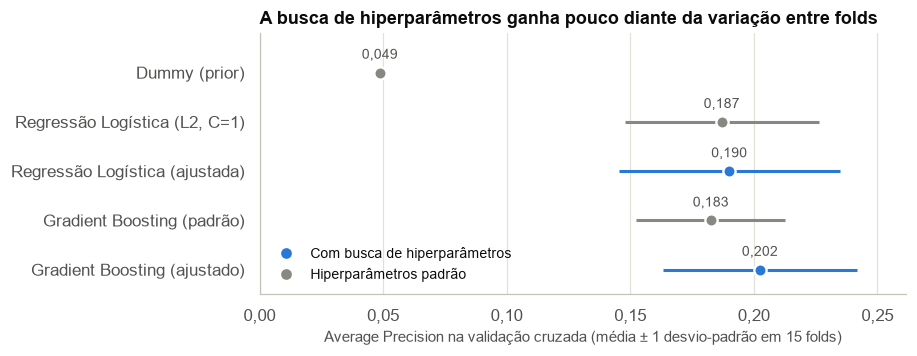

In [7]:
# Comparação dos cinco modelos: média e desvio-padrão da AP nos 15 folds
ordem = ["Dummy (prior)", "Regressão Logística (L2, C=1)", "Regressão Logística (ajustada)",
         "Gradient Boosting (padrão)", "Gradient Boosting (ajustado)"]
fig, ax = plt.subplots(figsize=(8.5, 3.4))
for i, nome in enumerate(ordem):
    s = scores[nome]
    cor = AZUL if "ajustad" in nome else NEUTRO
    ax.errorbar(s.mean(), i, xerr=s.std(ddof=1), fmt="o", color=cor, ecolor=cor, elinewidth=2,
                capsize=0, markersize=8, markeredgecolor="white", markeredgewidth=1.5)
    ax.annotate(br(s.mean()), (s.mean(), i), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=9, color=TINTA_2)
ax.set_yticks(range(len(ordem)), ordem)
ax.set_ylim(len(ordem) - 0.5, -0.8)
ax.set_xlim(0, max(s.mean() + s.std(ddof=1) for s in scores.values()) + 0.02)
ax.grid(axis="y", visible=False)
virgula(ax, "x")
ax.set_xlabel("Average Precision na validação cruzada (média ± 1 desvio-padrão em 15 folds)")
ax.set_title("A busca de hiperparâmetros ganha pouco diante da variação entre folds")
ax.plot([], [], "o", color=AZUL, label="Com busca de hiperparâmetros")
ax.plot([], [], "o", color=NEUTRO, label="Hiperparâmetros padrão")
ax.legend(loc="lower left")
fig.tight_layout()
salvar(fig, "01_comparacao_modelos")

A busca trouxe ganho pequeno: a regressão logística passou de 0,187 para 0,190, e o Gradient Boosting, de 0,183 para 0,202. O Gradient Boosting ajustado é o melhor modelo até aqui, mas sua vantagem sobre a regressão logística (+0,012; IC 95% de -0,027 a +0,052; p = 0,51) não é estatisticamente significativa. Esses valores são levemente otimistas, pois cada um é o máximo entre muitas configurações; a estimativa sem esse viés virá do teste.

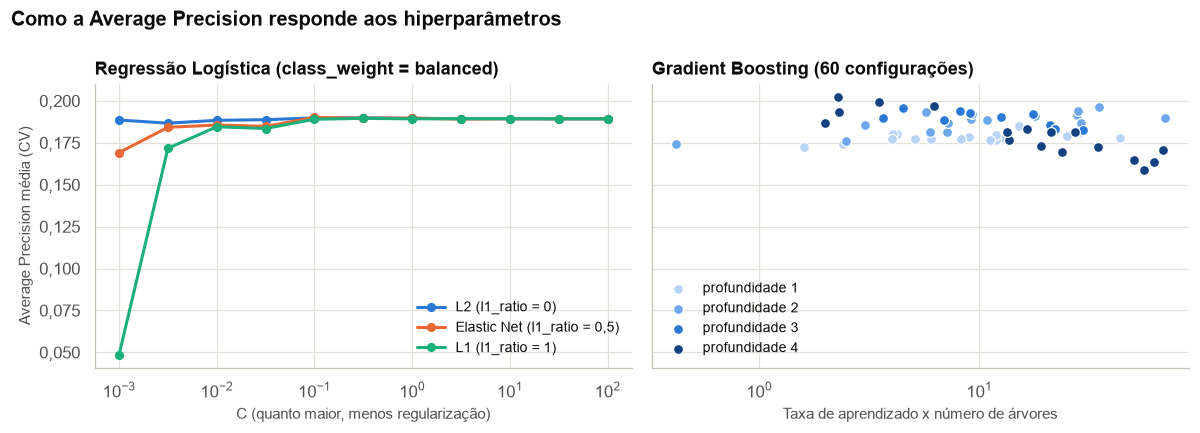

In [8]:
# Sensibilidade da métrica aos hiperparâmetros de cada busca
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

# Painel 1: regressão logística, com o class_weight escolhido pela busca
res_lr = pd.DataFrame(busca_lr.cv_results_)
peso = busca_lr.best_params_["clf__class_weight"]
filtro = res_lr["param_clf__class_weight"].isna() if peso is None else res_lr["param_clf__class_weight"].eq(peso)
rotulos = {0.0: "L2 (l1_ratio = 0)", 0.5: "Elastic Net (l1_ratio = 0,5)", 1.0: "L1 (l1_ratio = 1)"}
for (razao, rotulo), cor in zip(rotulos.items(), [AZUL, LARANJA, VERDE]):
    d = res_lr[filtro & res_lr["param_clf__l1_ratio"].astype(float).eq(razao)].copy()
    d["C"] = d["param_clf__C"].astype(float)
    d = d.sort_values("C")
    ax1.plot(d["C"], d["mean_test_score"], color=cor, marker="o", markersize=5, label=rotulo)
ax1.set_xscale("log")
ax1.set_xlabel("C (quanto maior, menos regularização)")
ax1.set_ylabel("Average Precision média (CV)")
virgula(ax1, "y", 3)
ax1.set_title(f"Regressão Logística (class_weight = {peso})")
ax1.legend(loc="lower right")

# Painel 2: Gradient Boosting, relacionando a taxa de aprendizado ao número de árvores
res_gb = pd.DataFrame(busca_gb.cv_results_)
res_gb["passo_total"] = res_gb["param_clf__learning_rate"].astype(float) * res_gb["param_clf__n_estimators"].astype(float)
tons = {1: "#b7d3f6", 2: "#6da7ec", 3: "#2a78d6", 4: "#104281"}
for prof, cor in tons.items():
    d = res_gb[res_gb["param_clf__max_depth"].astype(int).eq(prof)]
    ax2.scatter(d["passo_total"], d["mean_test_score"], s=42, color=cor, edgecolor="white",
                linewidth=0.8, label=f"profundidade {prof}")
ax2.set_xscale("log")
ax2.set_xlabel("Taxa de aprendizado x número de árvores")
ax2.set_title("Gradient Boosting (60 configurações)")
ax2.legend(loc="lower left")
fig.suptitle("Como a Average Precision responde aos hiperparâmetros", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
fig.tight_layout()
salvar(fig, "02_sensibilidade_hiperparametros")

**Regressão logística:** a AP fica estável para `C` a partir de 0,1. Só a penalidade forte prejudica o modelo: com L1 e `C = 0,001`, ele deixa de discriminar e a AP cai ao nível do Dummy.

**Gradient Boosting:** árvores de profundidade 1, sem interações, ficam perto de 0,175. As melhores configurações têm profundidade 3 ou 4 com poucos passos de aprendizado. Com profundidade 4 e muitos passos, a AP cai para cerca de 0,16, sinal de sobreajuste. Interações ajudam, mas precisam de controle.

### 1.3 Mudança no pipeline: indicador de `bmi` ausente

**Correção da APS1.** A APS1 afirmou que não havia evidência de associação entre a ausência de `bmi` e o *target*. Verificando no treino, o dado mostra o contrário.

AVC com bmi ausente   : 21.8% (37 de 170)
AVC com bmi registrado: 4.1% (162 de 3918)
Razão de chances bruta: 6.45 (Fisher, p = 1.5e-15)
Razão de chances ajustada: 4.18


mean          sum        size      
bmi_ausente  False  True  False True  False True 
faixa                                            
até 40      0.0012 0.0213     2     1  1733    47
41 a 60     0.0411 0.1522    50     7  1218    46
61 a 70     0.0778 0.2917    35     7   450    24
mais de 70  0.1451 0.4151    75    22   517    53

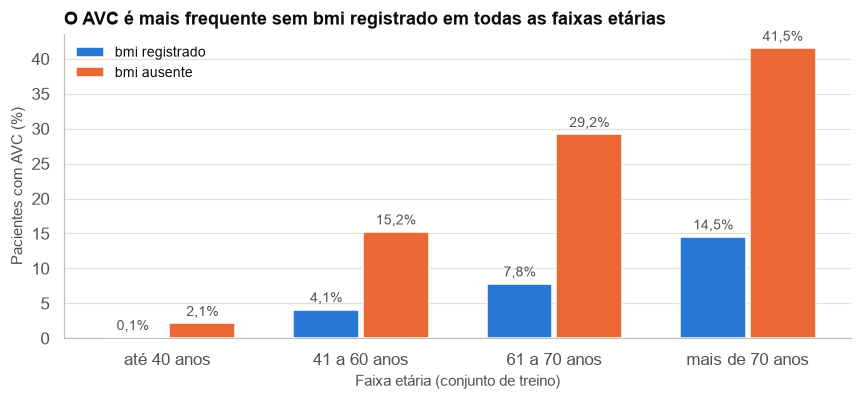

In [9]:
# Revisão de um achado da APS1, usando apenas o treino: a ausência de bmi se associa ao AVC?
ausente = X_train["bmi"].isna()
tabela_2x2 = [[y_train[ausente].sum(), (1 - y_train[ausente]).sum()],
              [y_train[~ausente].sum(), (1 - y_train[~ausente]).sum()]]
razao_chances, p_fisher = stats.fisher_exact(tabela_2x2)
taxa_ausente, taxa_presente = y_train[ausente].mean(), y_train[~ausente].mean()
print(f"AVC com bmi ausente   : {taxa_ausente:.1%} ({y_train[ausente].sum()} de {ausente.sum()})")
print(f"AVC com bmi registrado: {taxa_presente:.1%} ({y_train[~ausente].sum()} de {(~ausente).sum()})")
print(f"Razão de chances bruta: {razao_chances:.2f} (Fisher, p = {p_fisher:.1e})")

# Razão de chances ajustada pelas demais variáveis (regularização quase nula)
ajuste = modelo(
    Pipeline([("preprocessor", ColumnTransformer(
        transformadores_aps1() + [("bmi_ausente", MissingIndicator(features="all"), ["bmi"])]
    ))]),
    LogisticRegression(C=1e3, max_iter=20000),
).fit(X_train, y_train)
or_ajustada = float(np.exp(ajuste.named_steps["clf"].coef_[0][-1]))
print(f"Razão de chances ajustada: {or_ajustada:.2f}")
resultados["bmi_ausente"] = {"taxa_ausente": float(taxa_ausente), "taxa_presente": float(taxa_presente),
                             "n_ausente": int(ausente.sum()), "avc_ausente": int(y_train[ausente].sum()),
                             "or_bruta": float(razao_chances), "p_fisher": float(p_fisher), "or_ajustada": or_ajustada}

# A associação resiste quando comparamos pacientes da mesma faixa etária?
faixas = pd.cut(X_train["age"], [0, 40, 60, 70, 100], labels=["até 40", "41 a 60", "61 a 70", "mais de 70"])
por_faixa = (pd.DataFrame({"faixa": faixas, "bmi_ausente": ausente, "avc": y_train})
             .groupby(["faixa", "bmi_ausente"], observed=True)["avc"].agg(["mean", "sum", "size"]).unstack())
display(por_faixa)
resultados["bmi_por_faixa"] = {str(k): {f"{a}_{b}": float(v) for (a, b), v in linha.items()}
                               for k, linha in por_faixa.iterrows()}

fig, ax = plt.subplots(figsize=(8, 3.8))
pos = np.arange(len(por_faixa))
larg = 0.34
b1 = ax.bar(pos - larg / 2 - 0.01, por_faixa[("mean", False)] * 100, larg, color=AZUL, label="bmi registrado")
b2 = ax.bar(pos + larg / 2 + 0.01, por_faixa[("mean", True)] * 100, larg, color=LARANJA, label="bmi ausente")
for barras in (b1, b2):
    ax.bar_label(barras, labels=[f"{br(b.get_height(), 1)}%" for b in barras], padding=3, fontsize=9, color=TINTA_2)
ax.set_xticks(pos, [f"{f} anos" for f in por_faixa.index])
ax.grid(axis="x", visible=False)
ax.set_ylabel("Pacientes com AVC (%)")
ax.set_xlabel("Faixa etária (conjunto de treino)")
ax.set_title("O AVC é mais frequente sem bmi registrado em todas as faixas etárias")
ax.legend(loc="upper left")
fig.tight_layout()
salvar(fig, "03_bmi_ausente_por_idade")

AVC ocorre em 21,8% dos pacientes sem `bmi` registrado e em 4,1% dos demais (razão de chances de 6,45; teste de Fisher, p ≈ 1,5 × 10⁻¹⁵). A diferença aparece em todas as faixas etárias e resiste ao ajuste pelas demais variáveis (razão de chances ajustada de 4,18). Ao imputar a mediana, o pipeline da APS1 trata esses pacientes como casos comuns e apaga essa informação.

**Mudança proposta:** acrescentar um indicador binário de `bmi` ausente como terceiro ramo do `ColumnTransformer`, passando de 23 para 24 colunas. O restante do pipeline não muda. O `RobustScaler`, citado na APS1 como alternativa, não foi escolhido porque árvores de decisão dependem apenas da ordem dos valores e seriam indiferentes a ele.

**Risco assumido:** o indicador pode ser vazamento de dados (*leakage*; Kapoor; Narayanan, 2023). Se o `bmi` deixou de ser registrado porque o paciente já chegou com AVC, a ausência é consequência do desfecho e não estaria disponível para prever um caso futuro. A documentação do dataset não permite confirmar nem descartar essa hipótese. Por isso, a Seção 2.6 mede quanto o resultado depende do indicador.

In [10]:
def pipeline_com_indicador():
    """Pipeline da APS1 + indicador binário de bmi ausente, sem escala, como as colunas one-hot.

    features="all" mantém a coluna mesmo em um fold sem ausências, e a imputação
    por mediana da APS1 continua igual: o indicador é a única diferença.
    """
    return Pipeline(steps=[("preprocessor", ColumnTransformer(
        transformadores_aps1() + [("bmi_ausente", MissingIndicator(features="all"), ["bmi"])]
    ))])

# Nova seleção de hiperparâmetros: mesmos espaços de busca, folds, métrica e semente
busca_lr_ind = buscar_lr(pipeline_com_indicador())
busca_gb_ind = buscar_gb(pipeline_com_indicador())

candidatos = {
    ("Regressão Logística", "APS1"): busca_lr,
    ("Gradient Boosting", "APS1"): busca_gb,
    ("Regressão Logística", "APS1 + indicador"): busca_lr_ind,
    ("Gradient Boosting", "APS1 + indicador"): busca_gb_ind,
}
tabela_mudanca = pd.DataFrame(
    {"AP média": {c: b.best_score_ for c, b in candidatos.items()},
     "desvio-padrão": {c: scores_da_busca(b).std(ddof=1) for c, b in candidatos.items()}}
)
tabela_mudanca.index.names = ["modelo", "pipeline"]
display(tabela_mudanca)

impacto = pd.DataFrame({
    "Regressão Logística": teste_t_corrigido(scores_da_busca(busca_lr_ind), scores_da_busca(busca_lr)),
    "Gradient Boosting": teste_t_corrigido(scores_da_busca(busca_gb_ind), scores_da_busca(busca_gb)),
}).T
impacto["folds com ganho"] = [
    (scores_da_busca(busca_lr_ind) > scores_da_busca(busca_lr)).mean(),
    (scores_da_busca(busca_gb_ind) > scores_da_busca(busca_gb)).mean(),
]
display(impacto)

print("Regressão Logística com indicador:", hiperparametros(busca_lr_ind))
print("Gradient Boosting com indicador  :", hiperparametros(busca_gb_ind))
resultados["mudanca"] = {" | ".join(k): v for k, v in tabela_mudanca.to_dict("index").items()}
resultados["impacto"] = impacto.to_dict("index")
resultados["hiperparametros_indicador"] = {"lr": hiperparametros(busca_lr_ind), "gb": hiperparametros(busca_gb_ind)}

# A regressão logística escolheu C no limite da grade: a métrica ainda subia ou já tinha estabilizado?
res_ind = pd.DataFrame(busca_lr_ind.cv_results_)
mesma_razao = res_ind["param_clf__l1_ratio"].astype(float).eq(busca_lr_ind.best_params_["clf__l1_ratio"])
sem_peso = res_ind["param_clf__class_weight"].isna()
plato = (res_ind[mesma_razao & sem_peso].assign(C=lambda d: d["param_clf__C"].astype(float))
         .sort_values("C")[["C", "mean_test_score"]].rename(columns={"mean_test_score": "AP média"}))
display(plato.reset_index(drop=True))
resultados["plato_c"] = plato.astype(float).to_dict("records")

,,AP média,desvio-padrão
modelo,pipeline,,
Regressão Logística,APS1,0.1901,0.0446
Gradient Boosting,APS1,0.2025,0.0393
Regressão Logística,APS1 + indicador,0.2248,0.0335
Gradient Boosting,APS1 + indicador,0.2517,0.0422


,delta,ic95_inf,ic95_sup,p,folds com ganho
Regressão Logística,0.0348,-0.0010,0.0705,0.0559,0.9333
Gradient Boosting,0.0492,-0.0034,0.1018,0.0646,0.8667


Regressão Logística com indicador: {'C': 100.0, 'class_weight': None, 'l1_ratio': 0.5}
Gradient Boosting com indicador  : {'learning_rate': 0.04683, 'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 25, 'n_estimators': 148, 'subsample': 0.98683}


,C,AP média
0,0.0010,0.0487
1,0.0032,0.1691
2,0.0100,0.1828
3,0.0316,0.1899
4,0.1000,0.2151
5,0.3162,0.2211
6,1.0000,0.2237
7,3.1623,0.2241
8,10.0000,0.2247
9,31.6228,0.2247


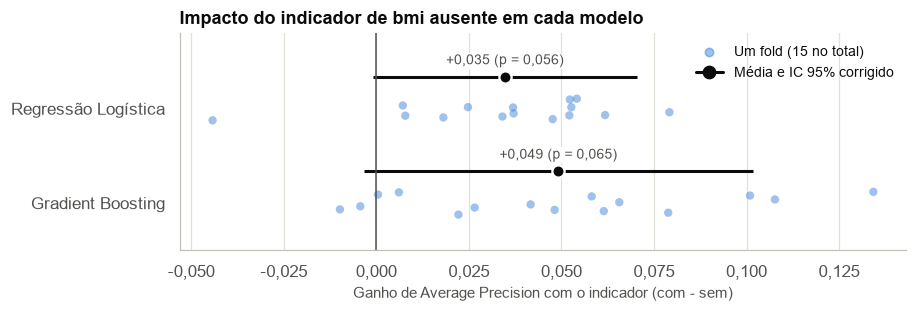

In [11]:
# Ganho fold a fold: cada ponto compara as duas versões exatamente nos mesmos dados
fig, ax = plt.subplots(figsize=(8.5, 3))
pares = [("Regressão Logística", busca_lr_ind, busca_lr), ("Gradient Boosting", busca_gb_ind, busca_gb)]
rng = np.random.default_rng(RANDOM_STATE)
for i, (nome, com, sem) in enumerate(pares):
    d = scores_da_busca(com) - scores_da_busca(sem)
    r = teste_t_corrigido(scores_da_busca(com), scores_da_busca(sem))
    ax.scatter(d, i + rng.uniform(-0.13, 0.13, len(d)), s=30, color=AZUL, alpha=0.45, edgecolor="none")
    ax.errorbar(r["delta"], i - 0.34, xerr=[[r["delta"] - r["ic95_inf"]], [r["ic95_sup"] - r["delta"]]],
                fmt="o", color=TINTA, markersize=8, elinewidth=2, markeredgecolor="white", markeredgewidth=1.5)
    ax.annotate(f"+{br(r['delta'])} (p = {br(r['p'])})", (r["delta"], i - 0.34), xytext=(0, 8),
                textcoords="offset points", ha="center", fontsize=9, color=TINTA_2,
                bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.axvline(0, color=TINTA_2, linewidth=1)
ax.set_yticks(range(len(pares)), [p[0] for p in pares])
ax.set_ylim(len(pares) - 0.5, -0.8)
ax.grid(axis="y", visible=False)
virgula(ax, "x", 3)
ax.set_xlabel("Ganho de Average Precision com o indicador (com - sem)")
ax.set_title("Impacto do indicador de bmi ausente em cada modelo")
ax.scatter([], [], s=30, color=AZUL, alpha=0.45, label="Um fold (15 no total)")
ax.plot([], [], "o-", color=TINTA, markersize=8, label="Média e IC 95% corrigido")
ax.legend(loc="upper right")
fig.tight_layout()
salvar(fig, "04_impacto_indicador")

A nova seleção de hiperparâmetros usou os mesmos espaços de busca, folds, métrica e semente. O enunciado pede a avaliação no melhor modelo (Gradient Boosting); repetimos na regressão logística para verificar se a ordem entre os modelos mudaria.

O indicador elevou a AP do Gradient Boosting de 0,202 para 0,252 (+0,049) e a da regressão logística de 0,190 para 0,225 (+0,035), com ganho em 87% e 93% dos folds. A direção é consistente, mas o ganho não atinge significância de 5% no teste corrigido (p = 0,065 e 0,056): os intervalos de confiança incluem valores ligeiramente negativos. Tratamos esse resultado como evidência sugestiva, e não conclusiva.

A regressão logística escolheu `C = 100`, no limite da grade, mas estender a grade não mudaria o resultado: a AP está estável de `C = 1` (0,2237) a `C = 100` (0,2248). Nessa região a penalidade quase não atua, e regularizar mais só piora este modelo.

In [12]:
# Regra definida antes da avaliação no teste: o melhor modelo é o de maior AP média na CV
melhor_chave = max(candidatos, key=lambda c: candidatos[c].best_score_)
busca_melhor = candidatos[melhor_chave]
melhor_modelo = busca_melhor.best_estimator_

# Mesma família de modelo sem o indicador, usada apenas na análise de sensibilidade da Seção 2
modelo_sem_indicador = candidatos[(melhor_chave[0], "APS1")].best_estimator_

# Melhor modelo de cada família com o pipeline final, usados na Seção 3
lr_final, gb_final = busca_lr_ind.best_estimator_, busca_gb_ind.best_estimator_

segundo = sorted(candidatos, key=lambda c: candidatos[c].best_score_)[-2]
disputa = teste_t_corrigido(scores_da_busca(busca_melhor), scores_da_busca(candidatos[segundo]))
print(f"Melhor modelo: {melhor_chave[0]} com pipeline '{melhor_chave[1]}' (AP = {busca_melhor.best_score_:.4f})")
print(f"Segundo lugar: {segundo[0]} com pipeline '{segundo[1]}' (AP = {candidatos[segundo].best_score_:.4f})")
print("Diferença:", {k: round(v, 4) for k, v in disputa.items()})
resultados["melhor"] = {"modelo": melhor_chave[0], "pipeline": melhor_chave[1], "ap_cv": float(busca_melhor.best_score_),
                        "segundo": " | ".join(segundo), "ap_cv_segundo": float(candidatos[segundo].best_score_),
                        "disputa": disputa}

Melhor modelo: Gradient Boosting com pipeline 'APS1 + indicador' (AP = 0.2517)
Segundo lugar: Regressão Logística com pipeline 'APS1 + indicador' (AP = 0.2248)
Diferença: {'delta': 0.0268, 'ic95_inf': -0.0114, 'ic95_sup': 0.065, 'p': 0.1541}


**Melhor modelo: Gradient Boosting com o indicador** (AP de 0,252). A regra, fixada antes de olhar o teste, é escolher a maior AP média. A vantagem sobre a regressão logística com indicador (+0,027; IC 95% de -0,011 a +0,065; p = 0,15) não é significativa, portanto não há evidência de diferença real entre os dois nesta amostra.

### 1.4 Curvas de aprendizado do melhor modelo

,instâncias de treino,AP treino,dp treino,AP validação,dp validação
0,490,0.7972,0.0591,0.1561,0.0352
1,887,0.6379,0.0459,0.1875,0.0356
2,1284,0.5602,0.0395,0.2108,0.0488
3,1681,0.5132,0.0219,0.2148,0.0436
4,2078,0.4894,0.0238,0.2165,0.0355
5,2475,0.4755,0.0233,0.2234,0.0512
6,2872,0.4605,0.0247,0.2280,0.0380
7,3270,0.4404,0.0139,0.2462,0.0408


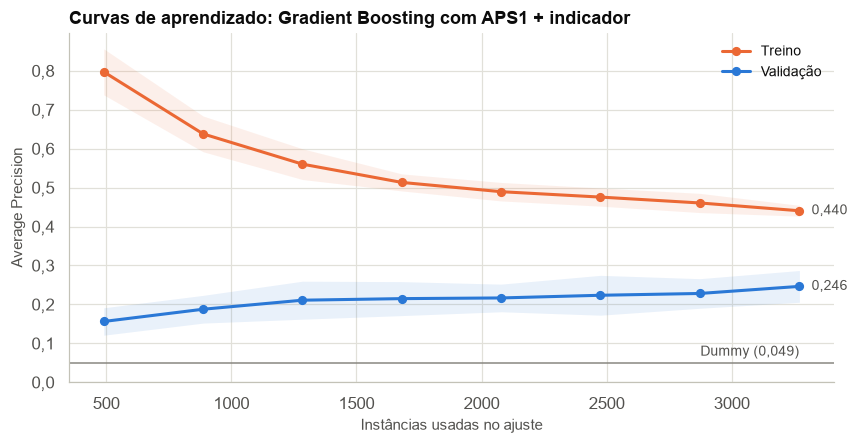

In [13]:
# Curvas de aprendizado do melhor modelo, com a mesma métrica e os mesmos folds
tamanhos, s_treino, s_val = learning_curve(
    melhor_modelo, X_train, y_train, cv=cv, scoring=METRICA, n_jobs=-1,
    train_sizes=np.linspace(0.15, 1.0, 8), shuffle=True, random_state=RANDOM_STATE,
)
curva = pd.DataFrame({
    "instâncias de treino": tamanhos, "AP treino": s_treino.mean(axis=1), "dp treino": s_treino.std(axis=1, ddof=1),
    "AP validação": s_val.mean(axis=1), "dp validação": s_val.std(axis=1, ddof=1),
})
display(curva)
resultados["curva_aprendizado"] = {k: [float(x) for x in v] for k, v in curva.to_dict("list").items()}

fig, ax = plt.subplots(figsize=(8, 4.2))
for coluna, dp, cor, rotulo in [("AP treino", "dp treino", LARANJA, "Treino"), ("AP validação", "dp validação", AZUL, "Validação")]:
    ax.plot(curva["instâncias de treino"], curva[coluna], color=cor, marker="o", markersize=5, label=rotulo)
    ax.fill_between(curva["instâncias de treino"], curva[coluna] - curva[dp], curva[coluna] + curva[dp], color=cor, alpha=0.1, linewidth=0)
    ax.annotate(br(curva[coluna].iloc[-1]), (curva["instâncias de treino"].iloc[-1], curva[coluna].iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=TINTA_2)
ax.axhline(prevalencia, color=NEUTRO, linewidth=1)
ax.annotate(f"Dummy ({br(prevalencia)})", (curva["instâncias de treino"].iloc[-1], prevalencia), xytext=(0, 5),
            textcoords="offset points", ha="right", fontsize=9, color=TINTA_2)
ax.set_ylim(0, None)
ax.set_xlabel("Instâncias usadas no ajuste")
ax.set_ylabel("Average Precision")
virgula(ax, "y", 1)
ax.set_title(f"Curvas de aprendizado: {melhor_chave[0]} com {melhor_chave[1]}")
ax.legend(loc="upper right")
fig.tight_layout()
salvar(fig, "05_curvas_aprendizado")

A AP de treino cai de 0,797 para 0,440 conforme a amostra cresce, enquanto a de validação sobe de 0,156 para 0,246. A distância de cerca de 0,19 entre as curvas ao final indica **alta variância**: o modelo ainda se ajusta a particularidades do treino. A curva de validação continua subindo, então mais dados, em especial mais casos de AVC, tendem a ajudar. O ganho dos últimos passos deve ser lido com cautela, pois o desvio-padrão entre folds é de cerca de 0,04.

O último ponto (0,246) difere da AP da busca (0,252) porque a curva embaralha as linhas e altera os sorteios internos do modelo. Essa diferença dá uma ideia do ruído de uma execução.

## 2. Avaliação do melhor modelo no conjunto de teste

### 2.1 Escolha do limiar de decisão

A AP não depende de limiar, mas Accuracy, Precision, Recall, F1 e a matriz de confusão dependem. O limiar padrão de 0,5 é inadequado para um evento raro. Escolhemos o limiar que **maximiza F2** nas predições *out-of-fold* do treino. O F2 pesa o recall mais do que a precisão, pois em uma triagem perder um AVC custa mais do que gerar um falso alarme.

{'F2 máximo (adotado)': 0.0928, 'F1 máximo': 0.0946, 'Recall de ao menos 80%': 0.05, '0,50 (padrão)': 0.5}


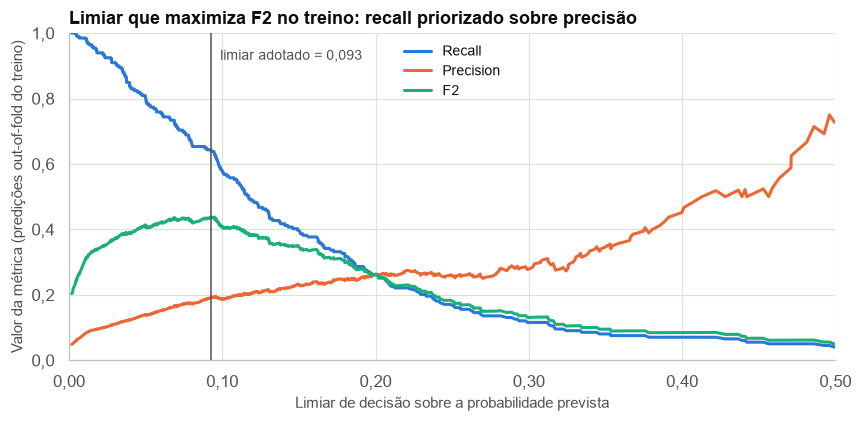

In [14]:
# Predições out-of-fold: cada paciente do treino é previsto por um modelo que não o viu.
# O conjunto de teste não participa da escolha do limiar.
cv_limiar = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def probabilidades_oof(pipe):
    return cross_val_predict(pipe, X_train, y_train, cv=cv_limiar, method="predict_proba", n_jobs=-1)[:, 1]

def limiares_candidatos(y_real, proba):
    """Calcula as curvas por limiar e o limiar indicado por cada critério."""
    precisao, revocacao, limiares = precision_recall_curve(y_real, proba)
    precisao, revocacao = precisao[:-1], revocacao[:-1]
    f1 = 2 * precisao * revocacao / np.clip(precisao + revocacao, 1e-12, None)
    f2 = 5 * precisao * revocacao / np.clip(4 * precisao + revocacao, 1e-12, None)
    curvas = pd.DataFrame({"limiar": limiares, "Precision": precisao, "Recall": revocacao, "F2": f2})
    escolhas = {
        "F2 máximo (adotado)": float(limiares[f2.argmax()]),
        "F1 máximo": float(limiares[f1.argmax()]),
        "Recall de ao menos 80%": float(limiares[np.where(revocacao >= 0.8)[0].max()]),
        "0,50 (padrão)": 0.5,
    }
    return curvas, escolhas

proba_oof = probabilidades_oof(melhor_modelo)
curvas_oof, limiares = limiares_candidatos(y_train, proba_oof)
limiar = limiares["F2 máximo (adotado)"]
print({k: round(v, 4) for k, v in limiares.items()})
resultados["limiares"] = limiares

fig, ax = plt.subplots(figsize=(8, 4))
visivel = curvas_oof[curvas_oof["limiar"] <= 0.5]
for coluna, cor in [("Recall", AZUL), ("Precision", LARANJA), ("F2", VERDE)]:
    ax.plot(visivel["limiar"], visivel[coluna], color=cor, label=coluna)
ax.axvline(limiar, color=TINTA_2, linewidth=1)
ax.annotate(f"limiar adotado = {br(limiar)}", (limiar, 0.93), xytext=(6, 0), textcoords="offset points",
            fontsize=9, color=TINTA_2, va="center")
ax.set_xlim(0, 0.5)
ax.set_ylim(0, 1)
virgula(ax, "x"); virgula(ax, "y", 1)
ax.set_xlabel("Limiar de decisão sobre a probabilidade prevista")
ax.set_ylabel("Valor da métrica (predições out-of-fold do treino)")
ax.set_title("Limiar que maximiza F2 no treino: recall priorizado sobre precisão")
ax.legend(loc="upper center")
fig.tight_layout()
salvar(fig, "06_escolha_limiar")

O limiar adotado é 0,093: pacientes com risco previsto a partir de 9,3% são sinalizados. A curva de F2 é quase plana nessa região (fica a menos de 2% do máximo entre 0,065 e 0,096), portanto o limiar exato é pouco determinado. A Seção 2.5 mede o efeito disso.

### 2.2 Accuracy, Precision, Recall e F1

Avaliação única do modelo, do pipeline e do limiar já fixados. Os intervalos de confiança vêm de *bootstrap* com 2.000 reamostragens, pois o teste tem apenas 50 AVCs.

In [15]:
# ÚNICA avaliação do modelo escolhido no teste. Modelo, pipeline e limiar já estão fixados.
proba_teste = melhor_modelo.predict_proba(X_test)[:, 1]
pred_teste = (proba_teste >= limiar).astype(int)

def metricas_limiar(y_real, proba, corte):
    pred = (proba >= corte).astype(int)
    return {"Accuracy": accuracy_score(y_real, pred),
            "Precision": precision_score(y_real, pred, zero_division=0),
            "Recall": recall_score(y_real, pred, zero_division=0),
            "F1": f1_score(y_real, pred, zero_division=0)}

def metricas_completas(y_real, proba, corte):
    return {**metricas_limiar(y_real, proba, corte),
            "ROC-AUC": roc_auc_score(y_real, proba),
            "Average Precision": average_precision_score(y_real, proba)}

def ic_bootstrap(y_real, proba, corte, repeticoes=2000):
    """IC 95% por bootstrap percentílico: o teste tem só 50 AVCs, então a incerteza é grande."""
    y_real, proba = np.asarray(y_real), np.asarray(proba)
    gerador = np.random.default_rng(RANDOM_STATE)
    linhas = []
    for _ in range(repeticoes):
        i = gerador.integers(0, len(y_real), len(y_real))
        if y_real[i].sum() > 0:
            linhas.append(metricas_completas(y_real[i], proba[i], corte))
    return pd.DataFrame(linhas).quantile([0.025, 0.975]).T

metricas_teste = metricas_completas(y_test, proba_teste, limiar)
ic_teste = ic_bootstrap(y_test, proba_teste, limiar)

# Referência sem habilidade: o Dummy nunca prevê AVC e dá a todos a mesma probabilidade
dummy = modelo(pipeline_aps1(), DummyClassifier(strategy="prior")).fit(X_train, y_train)
proba_dummy = dummy.predict_proba(X_test)[:, 1]
metricas_dummy = metricas_completas(y_test, proba_dummy, 0.5)

tabela_teste = pd.DataFrame({
    "Melhor modelo": metricas_teste,
    "IC 95% inferior": ic_teste[0.025],
    "IC 95% superior": ic_teste[0.975],
    "Dummy": metricas_dummy,
})
resultados["teste"] = tabela_teste.to_dict("index")
display(tabela_teste)

,Melhor modelo,IC 95% inferior,IC 95% superior,Dummy
Accuracy,0.8689,0.8474,0.8885,0.9511
Precision,0.2200,0.1558,0.2878,0.0000
Recall,0.6600,0.5283,0.7907,0.0000
F1,0.3300,0.2461,0.4132,0.0000
ROC-AUC,0.8395,0.7813,0.8929,0.5000
Average Precision,0.2402,0.1574,0.3648,0.0489


- **Accuracy (0,869):** é menor que a do Dummy (0,951), que nunca prevê AVC e por isso não detecta nenhum caso. Com esta prevalência, a métrica não ajuda a comparar os modelos.
- **Recall (0,660) e Precision (0,220):** o modelo detecta cerca de 2 em cada 3 AVCs, e 22% dos pacientes sinalizados tiveram AVC, 4,5 vezes a prevalência.
- **AP (0,240):** é próxima da estimativa da validação cruzada (0,252), o que indica que a seleção não superestimou muito o desempenho.
- **Incerteza:** os intervalos são largos. O recall, por exemplo, vai de 0,528 a 0,791.

### 2.3 Matriz de confusão

Falsos positivos: 117 | Falsos negativos: 17
Pacientes sinalizados: 150 de 1022 (14.7%)
Alertas por AVC detectado: 4.5


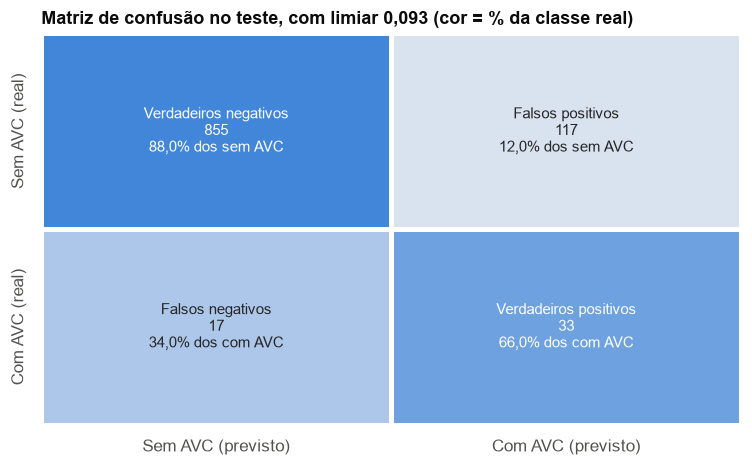

,limiar,Accuracy,Precision,Recall,F1,VP,FP,FN,VN
F2 máximo (adotado),0.0928,0.8689,0.2200,0.6600,0.3300,33.0000,117.0000,17.0000,855.0000
F1 máximo,0.0946,0.8699,0.2215,0.6600,0.3317,33.0000,116.0000,17.0000,856.0000
Recall de ao menos 80%,0.0500,0.7583,0.1470,0.8200,0.2492,41.0000,238.0000,9.0000,734.0000
"0,50 (padrão)",0.5000,0.9511,0.5000,0.0200,0.0385,1.0000,1.0000,49.0000,971.0000


In [16]:
vn, fp, fn, vp = confusion_matrix(y_test, pred_teste).ravel()
resultados["matriz_confusao"] = {"VN": int(vn), "FP": int(fp), "FN": int(fn), "VP": int(vp)}
print(f"Falsos positivos: {fp} | Falsos negativos: {fn}")
print(f"Pacientes sinalizados: {vp + fp} de {len(y_test)} ({(vp + fp) / len(y_test):.1%})")
print(f"Alertas por AVC detectado: {(vp + fp) / vp:.1f}")

matriz = np.array([[vn, fp], [fn, vp]])
taxa_linha = matriz / matriz.sum(axis=1, keepdims=True)
rotulos = np.array([
    [f"Verdadeiros negativos\n{vn}\n{br(taxa_linha[0, 0] * 100, 1)}% dos sem AVC",
     f"Falsos positivos\n{fp}\n{br(taxa_linha[0, 1] * 100, 1)}% dos sem AVC"],
    [f"Falsos negativos\n{fn}\n{br(taxa_linha[1, 0] * 100, 1)}% dos com AVC",
     f"Verdadeiros positivos\n{vp}\n{br(taxa_linha[1, 1] * 100, 1)}% dos com AVC"],
])
fig, ax = plt.subplots(figsize=(7, 4.4))
sns.heatmap(taxa_linha, annot=rotulos, fmt="", vmin=0, vmax=1, linewidths=2, linecolor="white",
            cmap=sns.light_palette(AZUL, as_cmap=True), cbar=False, ax=ax, annot_kws={"fontsize": 10},
            xticklabels=["Sem AVC (previsto)", "Com AVC (previsto)"], yticklabels=["Sem AVC (real)", "Com AVC (real)"])
ax.tick_params(left=False, bottom=False)
ax.set_title(f"Matriz de confusão no teste, com limiar {br(limiar)} (cor = % da classe real)")
fig.tight_layout()
salvar(fig, "07_matriz_confusao")

# O mesmo modelo em outros pontos de operação, definidos no treino e medidos no teste
linhas = {}
for nome, corte in limiares.items():
    pred = (proba_teste >= corte).astype(int)
    a, b, c, d = confusion_matrix(y_test, pred).ravel()
    linhas[nome] = {"limiar": corte, **metricas_limiar(y_test, proba_teste, corte), "VP": d, "FP": b, "FN": c, "VN": a}
pontos_operacao = pd.DataFrame(linhas).T
resultados["pontos_operacao"] = pontos_operacao.astype(float).to_dict("index")
display(pontos_operacao)

- **Falsos negativos (17):** AVCs não detectados, o erro mais grave em uma triagem.
- **Falsos positivos (117):** pacientes sem AVC registrado que seriam encaminhados para avaliação.
- **Carga de trabalho:** o modelo sinaliza 150 dos 1.022 pacientes (14,7%), ou 4,5 alertas por AVC detectado.

A tabela de pontos de operação mostra a troca entre esses erros, sem alterar o limiar adotado. Exigir recall de ao menos 80% no treino detecta mais 8 AVCs no teste, ao custo de 121 falsos positivos adicionais. O limiar de 0,5 detecta apenas 1 AVC. Neste modelo, os limiares de F1 e F2 praticamente coincidem.

### 2.4 Curva ROC e ROC-AUC

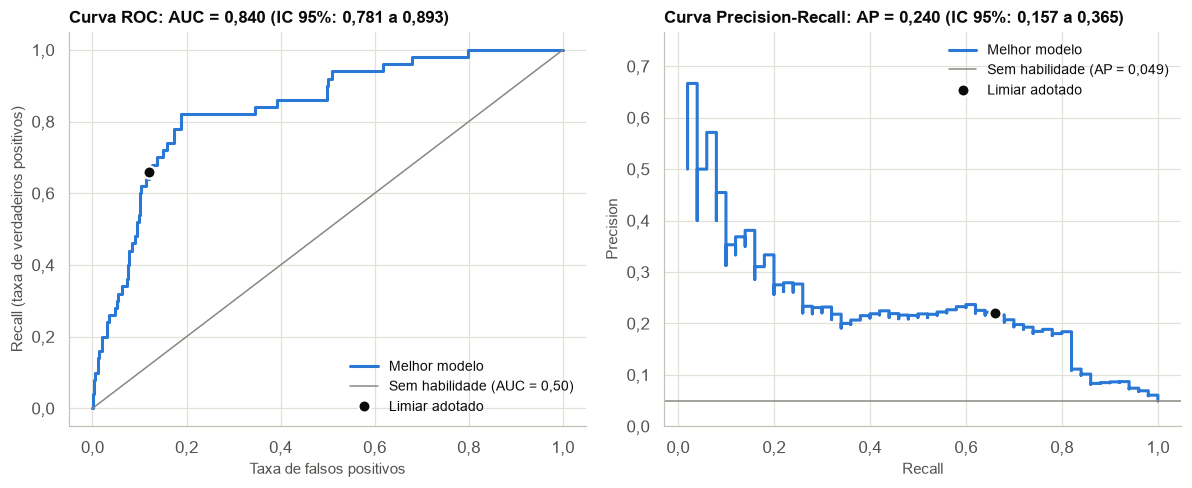

In [17]:
fpr, tpr, _ = roc_curve(y_test, proba_teste)
prec_c, rec_c, _ = precision_recall_curve(y_test, proba_teste)
fpr_op = fp / (fp + vn)
rec_op, prec_op = vp / (vp + fn), vp / (vp + fp)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6))
ax1.plot(fpr, tpr, color=AZUL, label="Melhor modelo")
ax1.plot([0, 1], [0, 1], color=NEUTRO, linewidth=1, label="Sem habilidade (AUC = 0,50)")
ax1.plot(fpr_op, rec_op, "o", color=TINTA, markersize=8, markeredgecolor="white", markeredgewidth=1.5, label="Limiar adotado")
ax1.set_xlabel("Taxa de falsos positivos")
ax1.set_ylabel("Recall (taxa de verdadeiros positivos)")
ax1.set_title(f"Curva ROC: AUC = {br(metricas_teste['ROC-AUC'])} "
              f"(IC 95%: {br(ic_teste.loc['ROC-AUC', 0.025])} a {br(ic_teste.loc['ROC-AUC', 0.975])})", fontsize=11)
ax1.legend(loc="lower right")

visiveis = rec_c > 0  # descarta o ponto artificial (recall 0, precision 1) que a curva acrescenta
ax2.step(rec_c[visiveis], prec_c[visiveis], where="post", color=AZUL, label="Melhor modelo")
ax2.axhline(y_test.mean(), color=NEUTRO, linewidth=1, label=f"Sem habilidade (AP = {br(y_test.mean())})")
ax2.plot(rec_op, prec_op, "o", color=TINTA, markersize=8, markeredgecolor="white", markeredgewidth=1.5, label="Limiar adotado")
ax2.set_xlabel("Recall")
ax2.set_ylabel("Precision")
ax2.set_ylim(0, min(1, prec_c[rec_c > 0.02].max() + 0.1))
ax2.set_title(f"Curva Precision-Recall: AP = {br(metricas_teste['Average Precision'])} "
              f"(IC 95%: {br(ic_teste.loc['Average Precision', 0.025])} a {br(ic_teste.loc['Average Precision', 0.975])})", fontsize=11)
ax2.legend(loc="upper right")
for eixo in (ax1, ax2):
    virgula(eixo, "x", 1); virgula(eixo, "y", 1)
fig.tight_layout()
salvar(fig, "08_curvas_roc_pr")

A ROC-AUC de 0,840 (IC 95% de 0,781 a 0,893) indica boa capacidade de ordenar pacientes por risco. A curva Precision-Recall mostra o outro lado: a precisão fica perto de 0,2 em boa parte da faixa de recall. Uma taxa de falsos positivos de apenas 12% gera 117 falsos alarmes porque há muito mais pacientes sem AVC do que com AVC. Esse contraste justifica a escolha da AP como métrica principal.

### 2.5 Estabilidade do limiar

In [18]:
# Estabilidade do limiar: repete a escolha por F2 em outras divisões do treino. O limiar adotado não
# muda; a célula apenas mede quanto o ponto de operação depende da divisão usada na escolha.
registros = []
for semente in range(10):
    divisao = StratifiedKFold(n_splits=5, shuffle=True, random_state=semente)
    oof = cross_val_predict(melhor_modelo, X_train, y_train, cv=divisao, method="predict_proba", n_jobs=-1)[:, 1]
    corte = limiares_candidatos(y_train, oof)[1]["F2 máximo (adotado)"]
    registros.append({"semente": semente, "limiar": corte, **metricas_limiar(y_test, proba_teste, corte)})
estabilidade = pd.DataFrame(registros)
display(estabilidade[["limiar", "Precision", "Recall", "F1"]].describe().loc[["min", "50%", "max"]])

# Sobre a curva do treino: em que faixa de limiares o F2 fica a menos de 2% do máximo?
quase_otimo = curvas_oof[curvas_oof["F2"] >= 0.98 * curvas_oof["F2"].max()]
print(f"F2 a menos de 2% do máximo para limiares entre {quase_otimo['limiar'].min():.3f} e {quase_otimo['limiar'].max():.3f}")
resultados["estabilidade_limiar"] = {
    "limiar_min": float(estabilidade["limiar"].min()), "limiar_mediana": float(estabilidade["limiar"].median()),
    "limiar_max": float(estabilidade["limiar"].max()), "recall_min": float(estabilidade["Recall"].min()),
    "recall_mediana": float(estabilidade["Recall"].median()), "recall_max": float(estabilidade["Recall"].max()),
    "precision_min": float(estabilidade["Precision"].min()), "precision_mediana": float(estabilidade["Precision"].median()),
    "precision_max": float(estabilidade["Precision"].max()),
    "quase_otimo_min": float(quase_otimo["limiar"].min()), "quase_otimo_max": float(quase_otimo["limiar"].max()),
}

,limiar,Precision,Recall,F1
min,0.0529,0.1507,0.6800,0.2547
50%,0.0699,0.1844,0.7800,0.2982
max,0.0884,0.2099,0.8200,0.3208


F2 a menos de 2% do máximo para limiares entre 0.065 e 0.096


Repetimos a escolha do limiar em 10 outras divisões do treino. O limiar variou de 0,053 a 0,088, e o recall no teste, de 0,68 a 0,82 (mediana de 0,78), com precisão de 0,15 a 0,21. O limiar adotado (0,093) ficou acima de todos eles, então o recall de 0,66 está na ponta conservadora do que o procedimento poderia produzir.

Mantivemos o limiar definido antes do teste, pois trocá-lo agora seria ajustá-lo ao teste. A conclusão prática é que o F2 não define um único ponto de operação com precisão. Em uso real, o limiar deveria considerar também a capacidade de atendimento.

### 2.6 Análise de sensibilidade: com e sem o indicador

In [19]:
# Análise de sensibilidade: o mesmo tipo de modelo, ajustado sem o indicador de bmi ausente.
# A escolha do modelo final já está fixada; esta comparação mede quanto do resultado depende do indicador.
proba_sem = modelo_sem_indicador.predict_proba(X_test)[:, 1]
_, limiares_sem = limiares_candidatos(y_train, probabilidades_oof(modelo_sem_indicador))
limiar_sem = limiares_sem["F2 máximo (adotado)"]

registrado = X_test["bmi"].notna().values
linhas = {
    "Com indicador, todos os pacientes": metricas_completas(y_test, proba_teste, limiar),
    "Sem indicador, todos os pacientes": metricas_completas(y_test, proba_sem, limiar_sem),
    "Com indicador, só com bmi registrado": metricas_completas(y_test[registrado], proba_teste[registrado], limiar),
    "Sem indicador, só com bmi registrado": metricas_completas(y_test[registrado], proba_sem[registrado], limiar_sem),
}
sensibilidade = pd.DataFrame(linhas).T
sensibilidade["limiar"] = [limiar, limiar_sem, limiar, limiar_sem]
display(sensibilidade)

# IC 95% pareado da diferença de AP: reamostra os mesmos pacientes nos dois modelos
gerador = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.values
difs = []
for _ in range(2000):
    i = gerador.integers(0, len(y_arr), len(y_arr))
    if y_arr[i].sum() > 0:
        difs.append(average_precision_score(y_arr[i], proba_teste[i]) - average_precision_score(y_arr[i], proba_sem[i]))
ic_dif = np.percentile(difs, [2.5, 97.5])
dif_ap = metricas_teste["Average Precision"] - average_precision_score(y_test, proba_sem)
print(f"Diferença de AP no teste (com - sem): {dif_ap:+.4f} | IC 95%: {ic_dif[0]:+.4f} a {ic_dif[1]:+.4f}")
taxa_sem_bmi, taxa_com_bmi = y_test[~registrado].mean(), y_test[registrado].mean()
print(f"Teste: {(~registrado).sum()} pacientes sem bmi, dos quais {y_test[~registrado].sum()} com AVC ({taxa_sem_bmi:.1%})")
print(f"Teste: {registrado.sum()} pacientes com bmi, dos quais {y_test[registrado].sum()} com AVC ({taxa_com_bmi:.1%})")
resultados["sensibilidade"] = sensibilidade.to_dict("index")
resultados["sensibilidade_dif_ap"] = {"delta": float(dif_ap), "ic95_inf": float(ic_dif[0]), "ic95_sup": float(ic_dif[1]),
                                      "n_sem_bmi_teste": int((~registrado).sum()), "avc_sem_bmi_teste": int(y_test[~registrado].sum()),
                                      "taxa_sem_bmi_teste": float(taxa_sem_bmi), "taxa_com_bmi_teste": float(taxa_com_bmi)}

,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,limiar
"Com indicador, todos os pacientes",0.8689,0.2200,0.6600,0.3300,0.8395,0.2402,0.0928
"Sem indicador, todos os pacientes",0.7965,0.1595,0.7400,0.2624,0.8327,0.2511,0.0664
"Com indicador, só com bmi registrado",0.8759,0.2246,0.6596,0.3351,0.8420,0.2436,0.0928
"Sem indicador, só com bmi registrado",0.8032,0.1606,0.7447,0.2642,0.8379,0.2306,0.0664


Diferença de AP no teste (com - sem): -0.0109 | IC 95%: -0.0612 a +0.0545
Teste: 31 pacientes sem bmi, dos quais 3 com AVC (9.7%)
Teste: 991 pacientes com bmi, dos quais 47 com AVC (4.7%)


**O ganho da validação cruzada não se repetiu no teste.** A AP foi de 0,240 com o indicador e 0,251 sem ele (diferença de -0,011; IC 95% de -0,061 a +0,054), e a ROC-AUC, de 0,840 e 0,833. O intervalo inclui tanto ganho quanto perda, portanto o teste não confirma nem descarta o efeito.

A amostra explica parte disso: o teste tem apenas 31 pacientes sem `bmi`, dos quais 3 com AVC. A taxa nesse grupo (9,7%, contra 4,7% dos demais) é bem menor que a do treino (21,8%).

Cada versão usa o próprio limiar de F2, então os pontos de operação diferem: com o indicador, Precision de 0,22 e Recall de 0,66; sem ele, 0,16 e 0,74.

Mantivemos o modelo escolhido pela regra definida antes do teste, pois trocá-lo agora seria usar o teste para selecionar. Para uso real, **a versão sem indicador é a alternativa mais segura** até que se esclareça por que o `bmi` está ausente.

## 3. Interpretação e explicabilidade

### 3.1 Modelo linear: as 3 maiores magnitudes

Analisamos a regressão logística ajustada com o pipeline final (`C = 100`, Elastic Net). As variáveis numéricas estão padronizadas, então seus coeficientes valem por 1 desvio-padrão; os das colunas one-hot valem para a presença da categoria.

In [20]:
def nomes_features(pipe):
    """Nomes das colunas após o pré-processamento, sem os prefixos do ColumnTransformer."""
    brutos = pipe.named_steps["preprocessamento"].get_feature_names_out()
    return [n.split("__", 1)[1].replace("missingindicator_bmi", "bmi_ausente") for n in brutos]

def variavel_original(nome):
    """Mapeia uma coluna one-hot para a variável original que a gerou."""
    return next((c for c in CATEGORICAS if nome.startswith(c + "_")), nome)

,feature,coeficiente,magnitude,razão de chances
0,age,1.6747,1.6747,5.3372
1,bmi_ausente,1.4324,1.4324,4.1889
2,work_type_Never_worked,-0.6735,0.6735,0.5099
3,hypertension_0,-0.6492,0.6492,0.5225
4,ever_married_Yes,-0.5948,0.5948,0.5517
5,heart_disease_0,-0.5240,0.5240,0.5921
6,Residence_type_Rural,-0.4837,0.4837,0.6165
7,Residence_type_Urban,-0.4251,0.4251,0.6537
8,work_type_children,0.4110,0.4110,1.5084
9,heart_disease_1,-0.3848,0.3848,0.6806


Desvios-padrão no treino: {'age': np.float64(22.59), 'avg_glucose_level': np.float64(45.25), 'bmi': np.float64(7.76)}
Coeficientes nulos: 0 de 24


,diferença de log-odds,razão de chances
work_type_Never_worked vs work_type_Private,-0.6442,0.5251
work_type_children vs work_type_Private,0.4403,1.5532
hypertension_1 vs hypertension_0,0.3896,1.4764
work_type_Self-employed vs work_type_Private,-0.2942,0.7451
ever_married_Yes vs ever_married_No,-0.2807,0.7552
smoking_status_smokes vs smoking_status_never smoked,0.2348,1.2646
smoking_status_formerly smoked vs smoking_status_never smoked,0.1910,1.2105
heart_disease_1 vs heart_disease_0,0.1392,1.1494
Residence_type_Urban vs Residence_type_Rural,0.0585,1.0603
gender_Male vs gender_Female,0.0368,1.0375


Razão de chances por 10 anos de idade: 2.10
work_type = Never_worked no treino: 13 pacientes, 0 AVCs


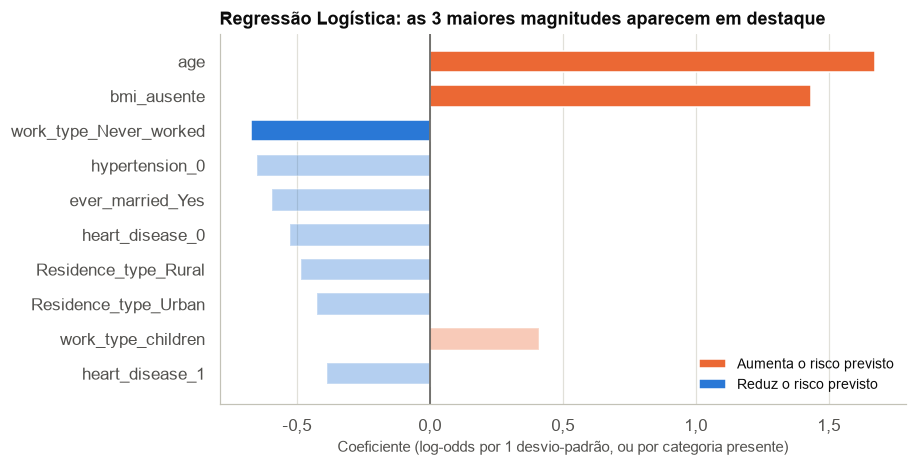

In [21]:
# Modelo linear com o pipeline final
clf_lr = lr_final.named_steps["clf"]
nomes_lr = nomes_features(lr_final)
coeficientes = pd.DataFrame({"feature": nomes_lr, "coeficiente": clf_lr.coef_[0]})
coeficientes["magnitude"] = coeficientes["coeficiente"].abs()
coeficientes["razão de chances"] = np.exp(coeficientes["coeficiente"])
coeficientes = coeficientes.sort_values("magnitude", ascending=False).reset_index(drop=True)
display(coeficientes.head(10))

# Desvio-padrão de cada variável numérica, para traduzir "por 1 desvio-padrão" na unidade original
escala = lr_final.named_steps["preprocessamento"].named_steps["preprocessor"].named_transformers_["num"].named_steps["scaler"]
desvios = dict(zip(NUMERICAS, escala.scale_))
print("Desvios-padrão no treino:", {k: round(v, 2) for k, v in desvios.items()})
print("Coeficientes nulos:", int((coeficientes["coeficiente"] == 0).sum()), "de", len(coeficientes))
resultados["coeficientes_lr"] = coeficientes.head(12).to_dict("records")

# O one-hot completo torna redundante uma coluna de cada variável: somar uma constante a todas as
# categorias e subtraí-la do intercepto não muda as previsões. Só a DIFERENÇA entre categorias é
# identificável, então estes contrastes são a leitura correta dos efeitos categóricos.
coef = dict(zip(nomes_lr, clf_lr.coef_[0]))
pares = [("hypertension_1", "hypertension_0"), ("heart_disease_1", "heart_disease_0"),
         ("ever_married_Yes", "ever_married_No"), ("gender_Male", "gender_Female"),
         ("Residence_type_Urban", "Residence_type_Rural"),
         ("smoking_status_formerly smoked", "smoking_status_never smoked"),
         ("smoking_status_smokes", "smoking_status_never smoked"),
         ("work_type_Self-employed", "work_type_Private"), ("work_type_children", "work_type_Private"),
         ("work_type_Never_worked", "work_type_Private")]
contrastes = pd.DataFrame({
    "diferença de log-odds": {f"{a} vs {b}": coef[a] - coef[b] for a, b in pares},
    "razão de chances": {f"{a} vs {b}": np.exp(coef[a] - coef[b]) for a, b in pares},
}).sort_values("diferença de log-odds", key=np.abs, ascending=False)
display(contrastes)

or_idade_10 = float(np.exp(coef["age"] * 10 / desvios["age"]))
nunca_trabalhou = X_train["work_type"].eq("Never_worked")
print(f"Razão de chances por 10 anos de idade: {or_idade_10:.2f}")
print(f"work_type = Never_worked no treino: {nunca_trabalhou.sum()} pacientes, {y_train[nunca_trabalhou].sum()} AVCs")
resultados["contrastes_lr"] = contrastes.to_dict("index")
resultados["or_idade_10"] = or_idade_10
resultados["never_worked"] = {"n": int(nunca_trabalhou.sum()), "avc": int(y_train[nunca_trabalhou].sum())}
resultados["desvios"] = {k: float(v) for k, v in desvios.items()}

fig, ax = plt.subplots(figsize=(8.5, 4.4))
top = coeficientes.head(10).iloc[::-1]
cores = [LARANJA if c > 0 else AZUL for c in top["coeficiente"]]
alfas = [1.0 if i >= len(top) - 3 else 0.35 for i in range(len(top))]
barras = ax.barh(top["feature"], top["coeficiente"], color=cores, height=0.62)
for barra, alfa in zip(barras, alfas):
    barra.set_alpha(alfa)
ax.axvline(0, color=TINTA_2, linewidth=1)
ax.grid(axis="y", visible=False)
virgula(ax, "x", 1)
ax.set_xlabel("Coeficiente (log-odds por 1 desvio-padrão, ou por categoria presente)")
ax.set_title("Regressão Logística: as 3 maiores magnitudes aparecem em destaque")
ax.barh([0], [0], color=LARANJA, label="Aumenta o risco previsto")
ax.barh([0], [0], color=AZUL, label="Reduz o risco previsto")
ax.legend(loc="lower right")
fig.tight_layout()
salvar(fig, "09_coeficientes_regressao_logistica")

**As 3 maiores magnitudes:**

1. **`age` (+1,675; razão de chances de 5,34 por desvio-padrão de 22,6 anos, ou 2,10 por década):** o maior efeito do modelo, coerente com a EDA.
2. **`bmi_ausente` (+1,432; razão de chances de 4,19):** mantidas as demais variáveis, a ausência de `bmi` multiplica por cerca de 4 a chance prevista, valor próximo ao estimado na Seção 1.3. Carrega o risco de vazamento discutido naquela seção.
3. **`work_type_Never_worked` (-0,673; razão de chances de 0,51):** não deve ser lido como proteção. A categoria tem 13 pacientes no treino, nenhum com AVC, e idade mediana de 17 anos.

**Cuidado com colunas one-hot.** Como o pipeline mantém todas as categorias, uma coluna de cada variável é redundante, e só a **diferença** entre categorias é identificável. `Residence_type_Rural` (-0,484) e `Residence_type_Urban` (-0,425) parecem importantes, mas a diferença entre elas é de apenas 0,059. A tabela de contrastes traz a leitura correta: hipertensão tem razão de chances de 1,48; doença cardíaca, de 1,15; e fumar em comparação a nunca ter fumado, de 1,26.

Esses valores são associações condicionais, e não efeitos causais comparáveis entre si (Westreich; Greenland, 2013).

### 3.2 Modelo ensemble: as 3 maiores importâncias

,feature,importância
0,age,0.4128
1,avg_glucose_level,0.1458
2,bmi_ausente,0.1306
3,bmi,0.0630
4,hypertension_1,0.0466
5,heart_disease_0,0.0306
6,hypertension_0,0.0285
7,heart_disease_1,0.0203
8,ever_married_No,0.0175
9,ever_married_Yes,0.0148


,variável,perda de AP,dp
0,age,0.1529,0.0145
1,avg_glucose_level,0.0246,0.0129
2,heart_disease,0.0189,0.0076
3,bmi,0.0134,0.0286
4,work_type,0.0070,0.0131
5,Residence_type,-0.0036,0.0034
6,smoking_status,-0.0038,0.0117
7,hypertension,-0.0038,0.0141
8,gender,-0.0124,0.0067
9,ever_married,-0.0161,0.0158


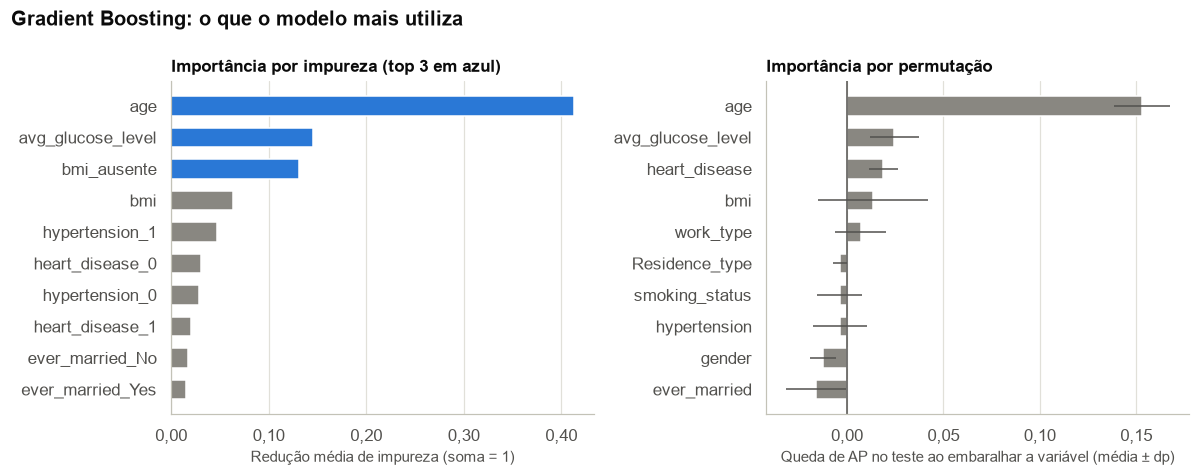

In [22]:
# Modelo ensemble: importância por impureza (nível da coluna codificada) e, para conferência,
# importância por permutação (nível da variável original), medida com a AP no teste.
clf_gb = gb_final.named_steps["clf"]
nomes_gb = nomes_features(gb_final)
importancia = pd.DataFrame({"feature": nomes_gb, "importância": clf_gb.feature_importances_}) \
    .sort_values("importância", ascending=False).reset_index(drop=True)
display(importancia.head(10))
resultados["importancia_gb"] = importancia.head(10).to_dict("records")

perm = permutation_importance(gb_final, X_test, y_test, scoring=METRICA, n_repeats=30,
                              random_state=RANDOM_STATE, n_jobs=-1)
permutacao = pd.DataFrame({"variável": X_test.columns, "perda de AP": perm.importances_mean, "dp": perm.importances_std}) \
    .sort_values("perda de AP", ascending=False).reset_index(drop=True)
display(permutacao)
resultados["permutacao_gb"] = permutacao.to_dict("records")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))
top = importancia.head(10).iloc[::-1]
cores = [AZUL if i >= len(top) - 3 else NEUTRO for i in range(len(top))]
ax1.barh(top["feature"], top["importância"], color=cores, height=0.62)
ax1.grid(axis="y", visible=False)
virgula(ax1, "x", 2)
ax1.set_xlabel("Redução média de impureza (soma = 1)")
ax1.set_title("Importância por impureza (top 3 em azul)", fontsize=11)

p = permutacao.iloc[::-1]
ax2.barh(p["variável"], p["perda de AP"], xerr=p["dp"], color=NEUTRO, height=0.62,
         error_kw=dict(ecolor=TINTA_2, elinewidth=1))
ax2.axvline(0, color=TINTA_2, linewidth=1)
ax2.grid(axis="y", visible=False)
virgula(ax2, "x", 2)
ax2.set_xlabel("Queda de AP no teste ao embaralhar a variável (média ± dp)")
ax2.set_title("Importância por permutação", fontsize=11)
fig.suptitle("Gradient Boosting: o que o modelo mais utiliza", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
salvar(fig, "10_importancia_gradient_boosting")

**As 3 maiores importâncias por impureza:**

1. **`age` (0,413):** a variável dominante, como na regressão logística.
2. **`avg_glucose_level` (0,146):** a EDA já mostrava glicemia mais alta entre os casos de AVC.
3. **`bmi_ausente` (0,131):** peso alto para uma coluna binária e rara, reflexo da associação vista no treino.

A importância por impureza é calculada no treino e pode favorecer variáveis com muitos valores possíveis (Strobl et al., 2007), então a conferimos por permutação no teste. Essa conferência confirma `age` (queda de AP de 0,153) e `avg_glucose_level` (0,025). Já `bmi`, que inclui o indicador porque embaralhar a coluna também embaralha as ausências, tem queda de 0,013 com desvio-padrão de 0,029, compatível com zero. O resultado concorda com a Seção 2.6.

### 3.3 SHAP no melhor modelo

O melhor modelo é um ensemble de árvores, então usamos o `TreeExplainer`, que calcula valores SHAP (Lundberg; Lee, 2017) de forma exata para árvores. Os valores estão em log-odds e somam, com o valor-base, a saída do modelo para cada paciente, propriedade conferida no código. Por essa aditividade, somamos as colunas one-hot para obter a contribuição de cada variável original.

**Importância global**

Aditividade conferida. Valor-base: -3.8904 = probabilidade 0.02


,média de |SHAP| (log-odds)
age,0.8293
ever_married,0.2666
hypertension,0.1416
avg_glucose_level,0.1177
bmi,0.1124
work_type,0.0898
smoking_status,0.0886
bmi_ausente,0.0821
gender,0.0457
heart_disease,0.0449


Idade mediana por ever_married: {'No': 18.0, 'Yes': 53.0}
SHAP médio de ever_married: {'No': -0.393, 'Yes': 0.194}
SHAP médio de bmi_ausente entre os 31 pacientes sem bmi: 1.066


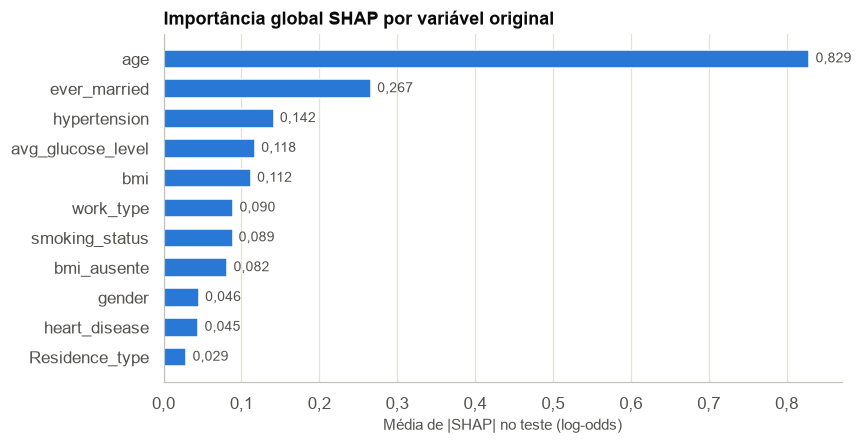

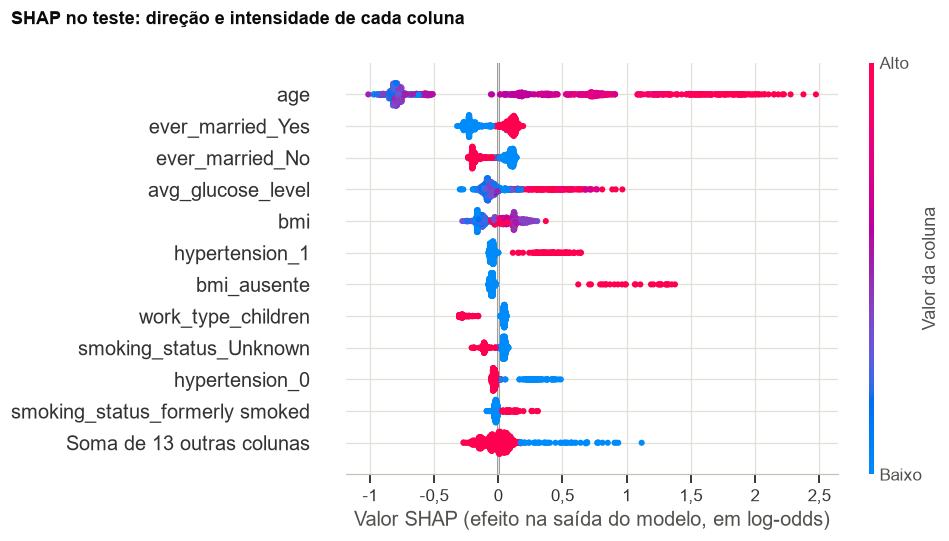

In [23]:
def traduzir_rotulo(rotulo, decimal):
    """Traduz rótulos nativos do shap e, nos eixos numéricos, troca o ponto decimal por vírgula."""
    rotulo = rotulo.replace("Sum of", "Soma de").replace("High", "Alto").replace("Low", "Baixo")
    rotulo = rotulo.replace("other features", "outras colunas" if rotulo.startswith("Soma") else "outras variáveis")
    return rotulo.replace(".", "{,}" if "$" in rotulo else ",") if decimal else rotulo

def ajustar_figura_shap(fig):
    """Coloca rótulos em português e vírgula decimal nas figuras nativas do shap."""
    for ax in fig.axes:
        for texto in ax.texts:
            texto.set_text(texto.get_text().replace(".", ","))
        for eixo, decimal in ((ax.xaxis, True), (ax.yaxis, False)):
            formato = eixo.get_major_formatter()
            if isinstance(formato, ScalarFormatter):
                if decimal:
                    eixo.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}".replace(".", ",")))
            else:
                eixo.set_major_formatter(FuncFormatter(lambda v, p, f=formato, d=decimal: traduzir_rotulo(f(v, p), d)))

# SHAP exato para árvores (TreeExplainer), calculado sobre as colunas pré-processadas do teste.
# Os valores estão em log-odds: base + soma dos valores = saída bruta do modelo para o paciente.
pre = melhor_modelo.named_steps["preprocessamento"]
clf_melhor = melhor_modelo.named_steps["clf"]
nomes_melhor = nomes_features(melhor_modelo)
X_teste_t = pre.transform(X_test)
X_teste_t = X_teste_t.toarray() if hasattr(X_teste_t, "toarray") else np.asarray(X_teste_t)

explicador = shap.TreeExplainer(clf_melhor)
explicacao = explicador(X_teste_t)
valores, base = explicacao.values, np.ravel(explicacao.base_values)

# Conferência da propriedade aditiva: a explicação precisa reconstruir a previsão do modelo
assert np.allclose(base + valores.sum(axis=1), clf_melhor.decision_function(X_teste_t), atol=1e-6)
print("Aditividade conferida. Valor-base:", round(float(base[0]), 4),
      "= probabilidade", round(float(1 / (1 + np.exp(-base[0]))), 4))

# Pelo axioma da aditividade, somar as colunas one-hot dá a contribuição da variável original
variaveis = list(dict.fromkeys(variavel_original(n) for n in nomes_melhor))
indices = {v: [i for i, n in enumerate(nomes_melhor) if variavel_original(n) == v] for v in variaveis}
valores_var = np.column_stack([valores[:, indices[v]].sum(axis=1) for v in variaveis])

importancia_shap = pd.Series(np.abs(valores_var).mean(axis=0), index=variaveis).sort_values(ascending=False)
resultados["shap_global"] = importancia_shap.to_dict()
display(importancia_shap.to_frame("média de |SHAP| (log-odds)"))

# Por que ever_married aparece em segundo lugar? Compara a idade nos dois grupos
idade_por_estado = X_test.groupby("ever_married")["age"].median()
print("Idade mediana por ever_married:", idade_por_estado.to_dict())
efeito_casado = pd.Series(valores_var[:, variaveis.index("ever_married")]).groupby(X_test["ever_married"].values).mean()
print("SHAP médio de ever_married:", efeito_casado.round(3).to_dict())

# bmi_ausente é raro: pouco peso na média global, mas efeito grande quando presente
efeito_ausente = valores_var[X_test["bmi"].isna().values, variaveis.index("bmi_ausente")]
print(f"SHAP médio de bmi_ausente entre os {len(efeito_ausente)} pacientes sem bmi: {efeito_ausente.mean():.3f}")
resultados["shap_detalhes"] = {"idade_mediana_ever_married": idade_por_estado.to_dict(),
                               "shap_medio_ever_married": efeito_casado.to_dict(),
                               "shap_medio_bmi_ausente": float(efeito_ausente.mean()),
                               "valor_base": float(base[0])}

fig, ax = plt.subplots(figsize=(8, 4.2))
s = importancia_shap.iloc[::-1]
barras = ax.barh(s.index, s.values, color=AZUL, height=0.62)
ax.bar_label(barras, labels=[br(v) for v in s.values], padding=4, fontsize=9, color=TINTA_2)
ax.grid(axis="y", visible=False)
virgula(ax, "x", 1)
ax.set_xlabel("Média de |SHAP| no teste (log-odds)")
ax.set_title("Importância global SHAP por variável original")
fig.tight_layout()
salvar(fig, "11_shap_importancia_global")

# Beeswarm: direção do efeito. Vermelho indica valor alto da coluna, azul indica valor baixo
explicacao_nomes = shap.Explanation(values=valores, base_values=base, data=X_teste_t, feature_names=nomes_melhor)
plt.figure()
shap.plots.beeswarm(explicacao_nomes, max_display=12, show=False, plot_size=(9, 5),
                    color_bar_label="Valor da coluna")
fig = plt.gcf()
fig.suptitle("SHAP no teste: direção e intensidade de cada coluna", x=0.02, ha="left", fontweight="bold", fontsize=12)
fig.axes[0].set_xlabel("Valor SHAP (efeito na saída do modelo, em log-odds)")
fig.tight_layout()
ajustar_figura_shap(fig)
salvar(fig, "12_shap_beeswarm")

- **`age` (0,829)** domina, com três vezes o peso da segunda variável. Quanto maior a idade, maior o risco previsto.
- **`ever_married` (0,267)** aparece em segundo, mas provavelmente funciona como substituto da idade: a idade mediana é de 18 anos entre os que nunca se casaram e de 53 entre os demais. Embaralhá-la não reduz a AP (Seção 3.2) porque as medidas respondem a perguntas diferentes: o SHAP mede quanto a variável move cada previsão, inclusive a de jovens de baixo risco, enquanto a AP depende principalmente da ordem no topo do ranking.
- **`hypertension` (0,142), `avg_glucose_level` (0,118) e `bmi` (0,112)** vêm a seguir. Hipertensão e glicose altas aumentam o risco. O efeito de `bmi` não é monotônico: valores baixos reduzem o risco, e valores intermediários são os que mais o aumentam.
- **`bmi_ausente` (0,082)** tem média baixa porque só 3% dos pacientes do teste estão nesse grupo. Para esses 31 pacientes, o efeito médio é de +1,07 log-odds, ou cerca de 2,9 vezes a chance.

**Três predições individuais**

Escolhemos três casos do teste: o verdadeiro positivo mais confiante, o falso positivo com maior probabilidade e o falso negativo com menor probabilidade. Cada gráfico parte do valor-base, E[f(X)] = -3,89 (probabilidade de 2,0%, abaixo da prevalência porque é uma média em log-odds), e soma as contribuições até a saída do modelo, f(x).

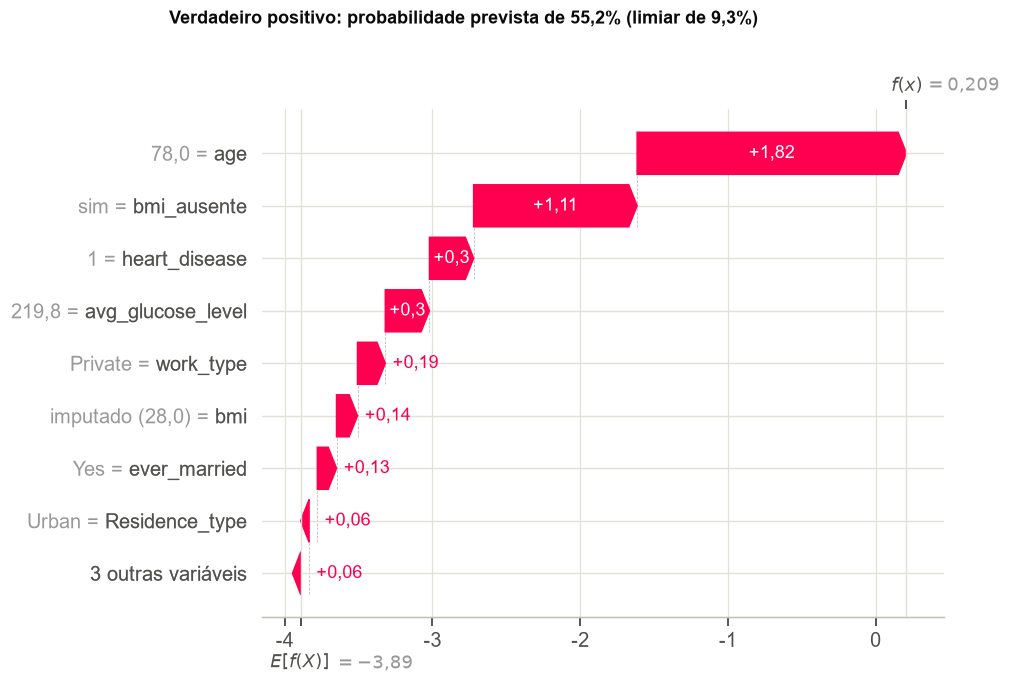


Verdadeiro positivo (paciente 13): probabilidade 55.2%
                   valor   SHAP
age                 78,0 1.8231
bmi_ausente          sim 1.1066
heart_disease          1 0.2992
avg_glucose_level  219,8 0.2987


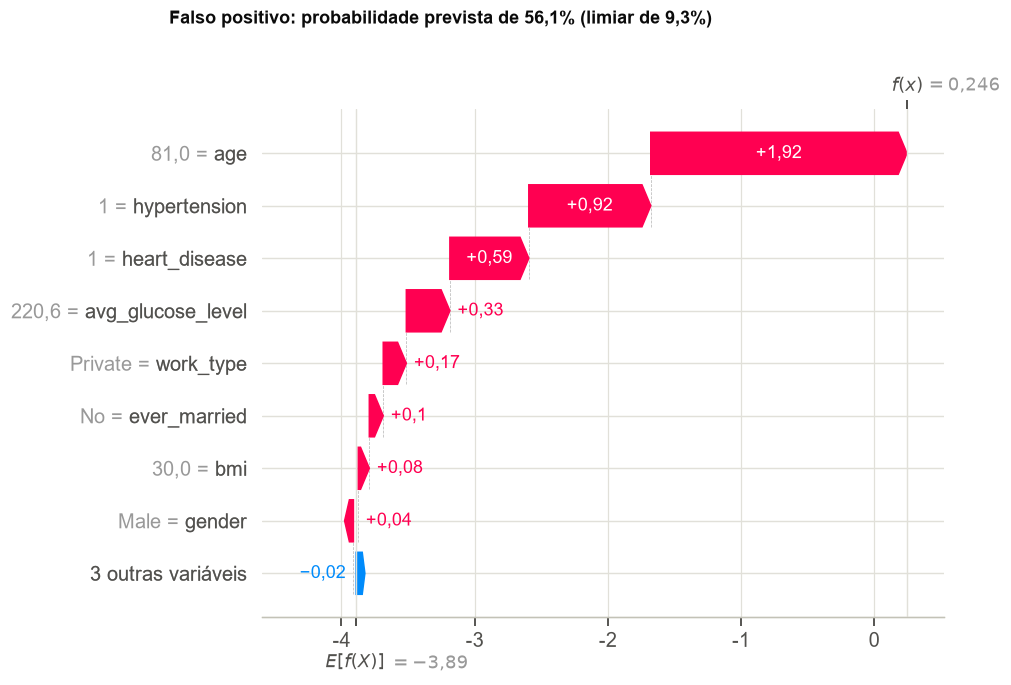


Falso positivo (paciente 3318): probabilidade 56.1%
                   valor   SHAP
age                 81,0 1.9239
hypertension           1 0.9158
heart_disease          1 0.5926
avg_glucose_level  220,6 0.3269


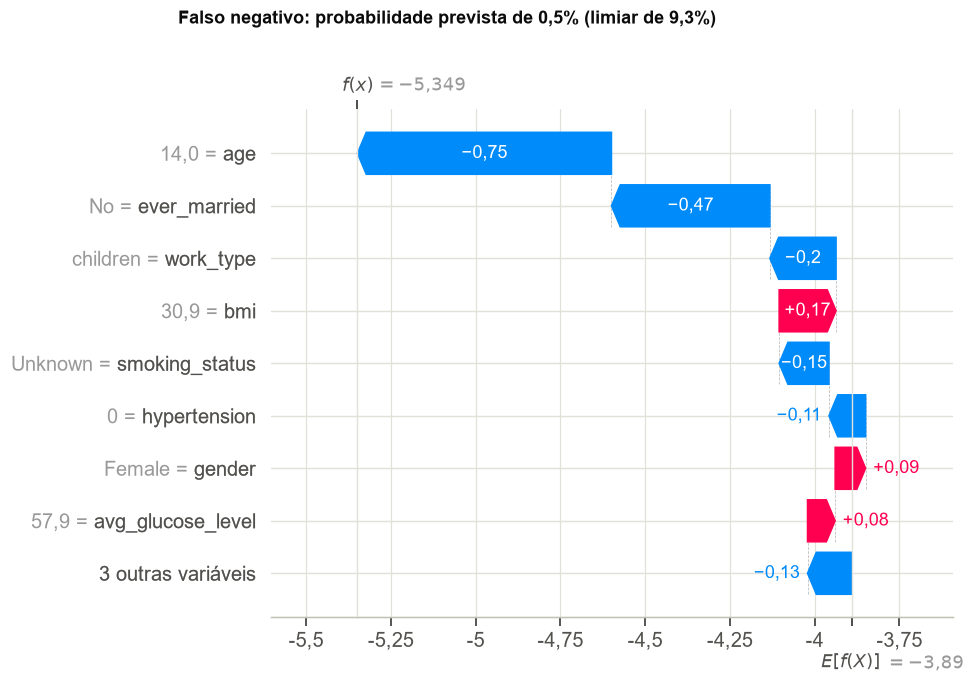


Falso negativo (paciente 245): probabilidade 0.5%
                 valor    SHAP
age               14,0 -0.7493
ever_married        No -0.4672
work_type     children -0.1953
bmi               30,9  0.1680


In [24]:
# Três casos instrutivos do teste: o acerto mais confiante, o alarme falso mais forte e o AVC mais perdido
casos_df = pd.DataFrame({"real": y_test.values, "proba": proba_teste}, index=X_test.index)
casos = {
    "Verdadeiro positivo": casos_df[(casos_df.real == 1) & (casos_df.proba >= limiar)].proba.idxmax(),
    "Falso positivo": casos_df[(casos_df.real == 0) & (casos_df.proba >= limiar)].proba.idxmax(),
    "Falso negativo": casos_df[(casos_df.real == 1) & (casos_df.proba < limiar)].proba.idxmin(),
}

def valor_exibido(variavel, paciente):
    """Valor legível da variável original, em vez do valor padronizado ou codificado."""
    if variavel == "bmi_ausente":
        return "sim" if pd.isna(paciente["bmi"]) else "não"
    valor = paciente[variavel]
    if variavel == "bmi" and pd.isna(valor):
        return "imputado (28,0)"
    return br(float(valor), 1) if variavel in NUMERICAS else str(valor)

def probabilidade(log_odds):
    return float(1 / (1 + np.exp(-log_odds)))

resumo_casos = {}
for arquivo, (tipo, indice) in zip(["13_shap_verdadeiro_positivo", "14_shap_falso_positivo", "15_shap_falso_negativo"], casos.items()):
    pos = X_test.index.get_loc(indice)
    paciente = X_test.loc[indice]
    dados = np.array([valor_exibido(v, paciente) for v in variaveis], dtype=object)
    exp = shap.Explanation(values=valores_var[pos], base_values=base[pos], data=dados, feature_names=variaveis)

    plt.figure()
    shap.plots.waterfall(exp, max_display=9, show=False)
    fig = plt.gcf()
    fig.suptitle(f"{tipo}: probabilidade prevista de {br(proba_teste[pos] * 100, 1)}% "
                 f"(limiar de {br(limiar * 100, 1)}%)", x=0.02, y=1.03, ha="left", fontweight="bold", fontsize=12)
    ajustar_figura_shap(fig)
    salvar(fig, arquivo)

    ordem_abs = np.argsort(-np.abs(valores_var[pos]))
    resumo_casos[tipo] = {
        "indice": int(indice), "real": int(y_test.loc[indice]), "proba": float(proba_teste[pos]),
        "dados": {v: valor_exibido(v, paciente) for v in variaveis},
        "contribuicoes": {variaveis[i]: float(valores_var[pos, i]) for i in ordem_abs},
    }
    print(f"\n{tipo} (paciente {indice}): probabilidade {proba_teste[pos]:.1%}")
    print(pd.DataFrame({"valor": [dados[i] for i in ordem_abs[:4]],
                        "SHAP": [valores_var[pos, i] for i in ordem_abs[:4]]},
                       index=[variaveis[i] for i in ordem_abs[:4]]).to_string())
resultados["shap_casos"] = resumo_casos

**Verdadeiro positivo (paciente 13, com AVC, probabilidade de 55,2%).** Homem de 78 anos com doença cardíaca, glicose de 219,8 e sem `bmi` registrado. As maiores contribuições são idade (+1,82), `bmi` ausente (+1,11), doença cardíaca (+0,30) e glicose (+0,30). Este acerto depende em parte do indicador questionado: sem essa contribuição, a decomposição aditiva daria cerca de 29%, ainda acima do limiar.

**Falso positivo (paciente 3318, sem AVC registrado, probabilidade de 56,1%).** Homem de 81 anos com hipertensão, doença cardíaca e glicose de 220,6. Idade (+1,92), hipertensão (+0,92), doença cardíaca (+0,59) e glicose (+0,33) explicam a previsão. O perfil é de alto risco, e um alerta aqui seria razoável: o rótulo indica apenas que não há AVC registrado.

**Falso negativo (paciente 245, com AVC, probabilidade de 0,5%).** Paciente de 14 anos, do sexo feminino, com `work_type = children` e sem hipertensão ou doença cardíaca. Idade (-0,75), `ever_married` (-0,47) e `work_type` (-0,20) reduzem o risco, e só o `bmi` de 30,9 (+0,17) o aumenta de forma relevante. As três maiores contribuições refletem, na prática, a pouca idade. O treino tem apenas 3 AVCs em 1.780 pacientes de até 40 anos, então o modelo tem pouco com que aprender esse padrão.

## 4. Discussão crítica

As limitações abaixo não foram tratadas nas seções anteriores. Os cálculos que as sustentam estão junto de cada uma.

### 4.1 Limitações do melhor modelo

In [25]:
# Evidência para a limitação 1: o desempenho é homogêneo entre grupos de pacientes?
def por_grupo(mascara):
    y_g, p_g = y_test[mascara], proba_teste[mascara]
    pred = (p_g >= limiar).astype(int)
    return {"pacientes": int(mascara.sum()), "AVCs": int(y_g.sum()), "taxa de AVC": y_g.mean(),
            "% sinalizados": pred.mean(),
            "Recall": recall_score(y_g, pred, zero_division=0),
            "Precision": precision_score(y_g, pred, zero_division=0)}

grupos = {
    "Idade abaixo de 60": (X_test["age"] < 60).values,
    "Idade de 60 ou mais": (X_test["age"] >= 60).values,
    "Feminino": (X_test["gender"] == "Female").values,
    "Masculino": (X_test["gender"] == "Male").values,
}
subgrupos = pd.DataFrame({nome: por_grupo(m) for nome, m in grupos.items()}).T
display(subgrupos)
resultados["subgrupos"] = subgrupos.astype(float).to_dict("index")

# IC exato (Clopper-Pearson) do recall abaixo de 60 anos e origem dos falsos negativos
jovem = (X_test["age"] < 60).values
acertos_jovem = int(((pred_teste == 1) & (y_test.values == 1) & jovem).sum())
ic_jovem = stats.binomtest(acertos_jovem, int(y_test[jovem].sum())).proportion_ci(method="exact")
fn_jovem = int(((pred_teste == 0) & (y_test.values == 1) & jovem).sum())
print(f"Recall abaixo de 60 anos: {acertos_jovem} de {int(y_test[jovem].sum())} | IC 95% exato: {ic_jovem.low:.1%} a {ic_jovem.high:.1%}")
print(f"Falsos negativos abaixo de 60 anos: {fn_jovem} de {fn}")
resultados["jovens"] = {"acertos": acertos_jovem, "avcs": int(y_test[jovem].sum()), "ic_sup": float(ic_jovem.high),
                        "fn_jovens": fn_jovem, "fn_total": int(fn)}

# Quanto o modelo acrescenta à idade? Modelo só com idade, na mesma validação cruzada do treino
so_idade = Pipeline([
    ("preprocessamento", ColumnTransformer([("num", StandardScaler(), ["age"])])),
    ("clf", LogisticRegression(max_iter=5000)),
])
ap_so_idade = cross_val_score(so_idade, X_train, y_train, cv=cv, scoring=METRICA, n_jobs=-1)
print(f"AP na CV, só com idade: {ap_so_idade.mean():.4f} | melhor modelo: {busca_melhor.best_score_:.4f}")
resultados["ap_so_idade"] = float(ap_so_idade.mean())

,pacientes,AVCs,taxa de AVC,% sinalizados,Recall,Precision
Idade abaixo de 60,750.0000,12.0000,0.0160,0.0147,0.0000,0.0000
Idade de 60 ou mais,272.0000,38.0000,0.1397,0.5110,0.8684,0.2374
Feminino,599.0000,29.0000,0.0484,0.1336,0.7586,0.2750
Masculino,423.0000,21.0000,0.0496,0.1655,0.5238,0.1571


Recall abaixo de 60 anos: 0 de 12 | IC 95% exato: 0.0% a 26.5%
Falsos negativos abaixo de 60 anos: 12 de 17
AP na CV, só com idade: 0.1691 | melhor modelo: 0.2517


**Limitação 1: o modelo não detecta AVC em pacientes mais jovens.** Abaixo de 60 anos, detectou 0 de 12 AVCs (IC 95% exato de 0% a 26,5%) e sinalizou 1,5% dos pacientes; a partir dos 60, detectou 86,8% e sinalizou 51,1%. Esses 12 casos são a maioria dos 17 falsos negativos. Também há diferença por sexo: recall de 75,9% no feminino e 52,4% no masculino, com precisão de 27,5% e 15,7%, embora com poucos eventos (29 e 21). Um modelo só com idade já alcança AP de 0,169 na validação cruzada, contra 0,252 do modelo completo, o que mostra quanto do desempenho vem dessa variável.

O desempenho agregado esconde esse padrão. O TRIPOD+AI recomenda reportar o desempenho em subgrupos relevantes (Collins et al., 2024). Um uso real exigiria avaliar o modelo por faixa etária e coletar mais casos em pacientes jovens.

Brier: modelo 0.0415 | Dummy 0.0465 | ganho 10.8%
Risco médio previsto 4.45% | taxa observada 4.89%


,prevista,observada,IC inf (Wilson),IC sup (Wilson),pacientes,AVCs
0,0.0032,0.0000,0.0000,0.0220,171,0
1,0.0061,0.0116,0.0032,0.0414,172,2
2,0.0108,0.0298,0.0128,0.0678,168,5
3,0.0259,0.0118,0.0032,0.0419,170,2
4,0.0587,0.0353,0.0163,0.0749,170,6
5,0.1617,0.2047,0.1510,0.2713,171,35


,prevalência,precision esperada
0,0.0100,0.0525
1,0.0200,0.1006
2,0.0500,0.2240
3,0.1000,0.3786


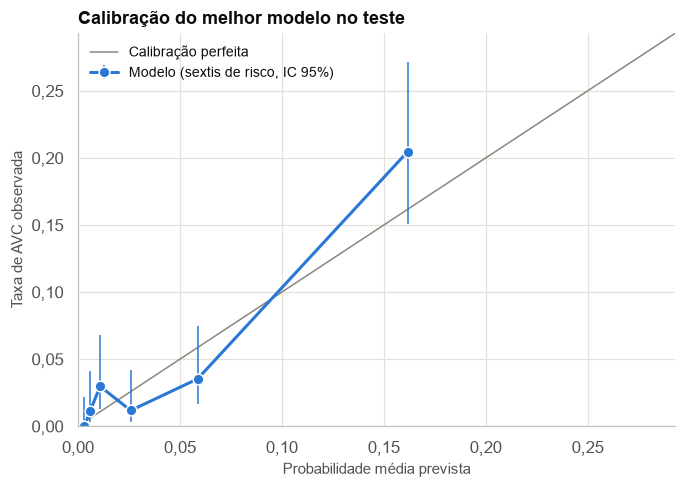

In [26]:
# Evidência para a limitação 2: as probabilidades previstas merecem confiança?
brier_modelo = brier_score_loss(y_test, proba_teste)
brier_dummy = brier_score_loss(y_test, proba_dummy)
media_prevista, media_observada = proba_teste.mean(), y_test.mean()
print(f"Brier: modelo {brier_modelo:.4f} | Dummy {brier_dummy:.4f} | ganho {1 - brier_modelo / brier_dummy:.1%}")
print(f"Risco médio previsto {media_prevista:.2%} | taxa observada {media_observada:.2%}")

observado, previsto = calibration_curve(y_test, proba_teste, n_bins=6, strategy="quantile")
grupos = pd.qcut(proba_teste, 6, duplicates="drop")
contagem = pd.Series(y_test.values).groupby(grupos, observed=True).agg(["size", "sum"])
z = 1.96
n = contagem["size"].values
centro = (observado + z**2 / (2 * n)) / (1 + z**2 / n)
margem = z * np.sqrt(observado * (1 - observado) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
calibracao = pd.DataFrame({"prevista": previsto, "observada": observado, "IC inf (Wilson)": np.clip(centro - margem, 0, 1),
                           "IC sup (Wilson)": np.clip(centro + margem, 0, 1), "pacientes": n, "AVCs": contagem["sum"].values})
display(calibracao)
resultados["calibracao"] = {"brier_modelo": float(brier_modelo), "brier_dummy": float(brier_dummy),
                            "media_prevista": float(media_prevista), "media_observada": float(media_observada),
                            "tabela": calibracao.astype(float).to_dict("records")}

# Com recall e especificidade fixos, a precisão depende da prevalência da população de uso
recall_op, especificidade = vp / (vp + fn), vn / (vn + fp)
precisao_prev = pd.DataFrame({"prevalência": [0.01, 0.02, 0.05, 0.10]})
precisao_prev["precision esperada"] = (recall_op * precisao_prev["prevalência"]) / (
    recall_op * precisao_prev["prevalência"] + (1 - especificidade) * (1 - precisao_prev["prevalência"]))
display(precisao_prev)
resultados["precisao_por_prevalencia"] = precisao_prev.to_dict("records")
resultados["operacao"] = {"recall": float(recall_op), "especificidade": float(especificidade)}

fig, ax = plt.subplots(figsize=(6.4, 4.6))
limite = max(calibracao["IC sup (Wilson)"].max(), calibracao["prevista"].max()) * 1.08
ax.plot([0, limite], [0, limite], color=NEUTRO, linewidth=1, label="Calibração perfeita")
ax.errorbar(calibracao["prevista"], calibracao["observada"],
            yerr=[calibracao["observada"] - calibracao["IC inf (Wilson)"], calibracao["IC sup (Wilson)"] - calibracao["observada"]],
            fmt="o-", color=AZUL, markersize=7, elinewidth=1, markeredgecolor="white", label="Modelo (sextis de risco, IC 95%)")
ax.set_xlim(0, limite); ax.set_ylim(0, limite)
virgula(ax, "x", 2); virgula(ax, "y", 2)
ax.set_xlabel("Probabilidade média prevista")
ax.set_ylabel("Taxa de AVC observada")
ax.set_title("Calibração do melhor modelo no teste")
ax.legend(loc="upper left")
fig.tight_layout()
salvar(fig, "16_calibracao")

**Limitação 2: as probabilidades e a precisão só valem para populações parecidas com esta amostra.** No teste, a calibração parece razoável: risco médio previsto de 4,45% contra 4,89% observado, e Brier de 0,0415 contra 0,0465 do Dummy. A evidência, porém, é fraca, pois 35 dos 50 AVCs estão no sexto de maior risco, em que o modelo prevê 16,2% e a taxa observada é de 20,5%.

Além disso, com o mesmo recall e a mesma especificidade, a precisão cairia de 22,4% em uma prevalência de 5% para 10,1% em uma de 2% e 5,2% em uma de 1%. Como não sabemos como a amostra foi formada, os 4,9% podem não representar a população de uso. Probabilidades mal calibradas podem prejudicar decisões clínicas (Van Calster et al., 2019), então a calibração precisaria ser verificada em dados externos antes de qualquer uso.

### 4.2 Limitações dos dados

**Limitação 1: origem e ordem temporal desconhecidas.** A página do dataset identifica a fonte apenas como *Confidential Source* e indica uso somente educacional (Fedesoriano, 2021). Não há informação sobre população, local, período ou critérios de inclusão. Também não há datas: não sabemos se glicose, `bmi`, tabagismo e comorbidades foram medidos antes do AVC, nem em que janela de tempo o `stroke` ocorreu. Portanto, as métricas descrevem associações nesta amostra, e não a previsão de um evento futuro. Preditores medidos depois do desfecho são uma forma conhecida de vazamento (Kapoor; Narayanan, 2023), que aqui não pode ser verificada.

**Limitação 2: faltam preditores clínicos importantes, e os disponíveis são grosseiros.** A base não traz fibrilação atrial, fator de risco independente para AVC (Wolf; Abbott; Kannel, 1991), nem valores de pressão arterial ou uso de anti-hipertensivos, presentes no perfil de risco de Framingham (Wolf et al., 1991). Também faltam fatores avaliados no INTERSTROKE, como atividade física, dieta, lipídios, álcool e fatores psicossociais; em conjunto, os fatores desse estudo responderam por cerca de 90% do risco atribuível populacional (O'Donnell et al., 2016).

Os dados disponíveis também são limitados: `hypertension` e `heart_disease` são binárias, `smoking_status` é `Unknown` em 30% dos registros, e `stroke` não separa AVC isquêmico de hemorrágico, que têm perfis de risco diferentes (O'Donnell et al., 2016). Essas lacunas ajudam a explicar a precisão baixa, que ajuste de hiperparâmetros não resolve.

### 4.3 Operacionalização e manutenção

**Ação 1: validação silenciosa e monitoramento contínuo.** Antes de influenciar qualquer decisão, o modelo rodaria em modo silencioso sobre pacientes reais: as previsões são registradas, mas não mostradas à equipe. Isso permite estimar o desempenho prospectivo e esclarecer por que o `bmi` fica ausente.

Em seguida, o monitoramento acompanharia a distribuição das entradas, a taxa de `bmi` ausente (4,2% no treino) e a de pacientes sinalizados (14,7% no teste) e, quando os desfechos forem conhecidos, AP, calibração e recall por faixa etária. Mudanças de tecnologia, população ou comportamento degradam modelos clínicos: um modelo de sepse amplamente usado precisou ser desativado em um hospital por alertas espúrios durante a pandemia (Finlayson et al., 2021).

**Ação 2: versionamento conjunto e atualização por gatilho.** Pré-processamento, modelo e limiar seriam distribuídos como um único artefato versionado, com versões fixas das bibliotecas e validação do esquema de entrada (tipos, faixas e categorias novas). Mudar uma parte afeta as demais, e essas dependências são fonte conhecida de dívida técnica em sistemas de ML (Sculley et al., 2015).

A atualização seria acionada pelo monitoramento, e não por calendário fixo, como recomendam Davis et al. (2017), que observaram a calibração piorar mesmo com a discriminação estável. Primeiro se recalibra o modelo. Só uma queda de discriminação justifica um novo ajuste, e cada nova versão precisa ser avaliada em dados recentes e por subgrupo antes de substituir a anterior.

## 5. Conclusão

- O Gradient Boosting com indicador de `bmi` ausente alcançou no teste AP de 0,240, cerca de 5 vezes a do Dummy (0,049), e ROC-AUC de 0,840. Com o limiar de F2, teve recall de 0,66 e precisão de 0,22.
- A idade concentra a maior parte do sinal, e o modelo não detectou nenhum dos 12 AVCs abaixo de 60 anos no teste.
- A mudança no pipeline corrigiu uma afirmação da APS1 e sugeriu ganho na validação cruzada, mas esse ganho não se confirmou no teste. A versão sem indicador é a alternativa mais segura para uso real.
- As diferenças entre os modelos são pequenas diante do ruído. A curva de aprendizado e os preditores ausentes indicam que o próximo ganho tende a vir de mais casos e de variáveis clínicas melhores, e não de modelos mais complexos.
- Qualquer uso clínico exigiria antes validação externa e prospectiva, verificação da calibração e avaliação por subgrupo.

In [27]:
# Exporta o modelo final (pré-processamento + estimador), o limiar e todos os resultados numéricos
joblib.dump({"modelo": melhor_modelo, "limiar": limiar, "versoes": versoes}, "artifacts/stroke_modelo_final.joblib")
with open("artifacts/aps2_resultados.json", "w", encoding="utf-8") as arquivo:
    json.dump(resultados, arquivo, ensure_ascii=False, indent=1, default=float)
print("Salvos: artifacts/stroke_modelo_final.joblib e artifacts/aps2_resultados.json")

Salvos: artifacts/stroke_modelo_final.joblib e artifacts/aps2_resultados.json


## Referências

1. BERGSTRA, J.; BENGIO, Y. Random search for hyper-parameter optimization. *Journal of Machine Learning Research*, v. 13, p. 281-305, 2012. Disponível em: <https://jmlr.org/papers/v13/bergstra12a.html>.
2. COLLINS, G. S. et al. TRIPOD+AI statement: updated guidance for reporting clinical prediction models that use regression or machine learning methods. *BMJ*, v. 385, e078378, 2024. DOI: [10.1136/bmj-2023-078378](https://doi.org/10.1136/bmj-2023-078378).
3. DAVIS, S. E. et al. Calibration drift in regression and machine learning models for acute kidney injury. *Journal of the American Medical Informatics Association*, v. 24, n. 6, p. 1052-1061, 2017. DOI: [10.1093/jamia/ocx030](https://doi.org/10.1093/jamia/ocx030).
4. FEDESORIANO. *Stroke Prediction Dataset*. Kaggle, 2021. Disponível em: <https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset>.
5. FINLAYSON, S. G. et al. The clinician and dataset shift in artificial intelligence. *New England Journal of Medicine*, v. 385, n. 3, p. 283-286, 2021. DOI: [10.1056/NEJMc2104626](https://doi.org/10.1056/NEJMc2104626).
6. FRIEDMAN, J. H. Greedy function approximation: a gradient boosting machine. *The Annals of Statistics*, v. 29, n. 5, p. 1189-1232, 2001. DOI: [10.1214/aos/1013203451](https://doi.org/10.1214/aos/1013203451).
7. KAPOOR, S.; NARAYANAN, A. Leakage and the reproducibility crisis in machine-learning-based science. *Patterns*, v. 4, n. 9, 100804, 2023. DOI: [10.1016/j.patter.2023.100804](https://doi.org/10.1016/j.patter.2023.100804).
8. LUNDBERG, S. M.; LEE, S.-I. A unified approach to interpreting model predictions. In: *Advances in Neural Information Processing Systems 30*, 2017. Disponível em: <https://papers.nips.cc/paper_files/paper/2017/hash/8a20a8621978632d76c43dfd28b67767-Abstract.html>.
9. NADEAU, C.; BENGIO, Y. Inference for the generalization error. *Machine Learning*, v. 52, p. 239-281, 2003. DOI: [10.1023/A:1024068626366](https://doi.org/10.1023/A:1024068626366).
10. O'DONNELL, M. J. et al. Global and regional effects of potentially modifiable risk factors associated with acute stroke in 32 countries (INTERSTROKE): a case-control study. *The Lancet*, v. 388, n. 10046, p. 761-775, 2016. DOI: [10.1016/S0140-6736(16)30506-2](https://doi.org/10.1016/S0140-6736(16)30506-2).
11. PEDREGOSA, F. et al. Scikit-learn: machine learning in Python. *Journal of Machine Learning Research*, v. 12, p. 2825-2830, 2011. Disponível em: <https://jmlr.org/papers/v12/pedregosa11a.html>.
12. SAITO, T.; REHMSMEIER, M. The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE*, v. 10, n. 3, e0118432, 2015. DOI: [10.1371/journal.pone.0118432](https://doi.org/10.1371/journal.pone.0118432).
13. SCULLEY, D. et al. Hidden technical debt in machine learning systems. In: *Advances in Neural Information Processing Systems 28*, p. 2503-2511, 2015. Disponível em: <https://proceedings.neurips.cc/paper/2015/file/86df7dcfd896fcaf2674f757a2463eba-Paper.pdf>.
14. STROBL, C. et al. Bias in random forest variable importance measures: illustrations, sources and a solution. *BMC Bioinformatics*, v. 8, 25, 2007. DOI: [10.1186/1471-2105-8-25](https://doi.org/10.1186/1471-2105-8-25).
15. VAN CALSTER, B. et al. Calibration: the Achilles heel of predictive analytics. *BMC Medicine*, v. 17, 230, 2019. DOI: [10.1186/s12916-019-1466-7](https://doi.org/10.1186/s12916-019-1466-7).
16. WESTREICH, D.; GREENLAND, S. The table 2 fallacy: presenting and interpreting confounder and modifier coefficients. *American Journal of Epidemiology*, v. 177, n. 4, p. 292-298, 2013. DOI: [10.1093/aje/kws412](https://doi.org/10.1093/aje/kws412).
17. WOLF, P. A.; ABBOTT, R. D.; KANNEL, W. B. Atrial fibrillation as an independent risk factor for stroke: the Framingham Study. *Stroke*, v. 22, n. 8, p. 983-988, 1991. DOI: [10.1161/01.STR.22.8.983](https://doi.org/10.1161/01.STR.22.8.983).
18. WOLF, P. A. et al. Probability of stroke: a risk profile from the Framingham Study. *Stroke*, v. 22, n. 3, p. 312-318, 1991.